# 03 — Exploratory Data Analysis
## Superstore Sales Analytics

Este notebook realiza a análise exploratória do dataset tratado e aprovado na etapa de preparação dos dados.

O objetivo é investigar distribuições, padrões, relações e comportamentos relevantes para o negócio, utilizando como fonte analítica o arquivo persistido em data/processed.

A análise será orientada por perguntas analíticas, de forma que cada transformação, métrica ou visualização possua um propósito definido. Os padrões identificados nesta etapa servirão como base para as análises especializadas posteriores de vendas, clientes, produtos, logística e comportamento temporal.

## 1. Configuração e Fonte Analítica

### 1.1 — Configuração do Ambiente e Caminhos

O notebook utiliza como fonte o dataset tratado e validado na etapa de preparação dos dados.

Os caminhos são definidos de forma relativa à raiz do projeto, preservando a portabilidade da estrutura e evitando dependências de caminhos absolutos do ambiente local.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


PROCESSED_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "sales_data_clean.parquet"
)

print(f"Raiz do projeto: {PROJECT_ROOT}")
print(f"Fonte analítica: {PROCESSED_DATA_PATH}")
print(f"Arquivo disponível: {PROCESSED_DATA_PATH.exists()}")

Raiz do projeto: c:\superstore-analytics
Fonte analítica: c:\superstore-analytics\data\processed\sales_data_clean.parquet
Arquivo disponível: True


### 1.2 — Carregamento da Camada Processada

A análise exploratória utiliza exclusivamente a camada processada gerada pelo pipeline de preparação dos dados.

O arquivo em formato Parquet é carregado como fonte analítica do notebook, garantindo que as análises subsequentes sejam realizadas sobre os dados previamente tratados e aprovados pelos controles de qualidade.

In [2]:
df = pd.read_parquet(PROCESSED_DATA_PATH)

print(f"Registros carregados: {len(df):,}")
print(f"Colunas carregadas: {df.shape[1]}")

Registros carregados: 9,799
Colunas carregadas: 19


### 1.3 — Validação Inicial da Fonte Analítica

Antes de iniciar a análise exploratória, a camada processada é submetida a uma validação inicial para confirmar que sua estrutura permanece compatível com o resultado aprovado na etapa de preparação.

Esta verificação não repete a auditoria completa de qualidade realizada anteriormente. Seu objetivo é estabelecer um quality gate de entrada para o EDA, confirmando a quantidade de registros e colunas, os tipos de dados e algumas condições essenciais para as análises subsequentes.

In [3]:
print(f"Dimensão do dataset: {df.shape}")
print()
print("Tipos de dados:")
print(df.dtypes)

Dimensão do dataset: (9799, 19)

Tipos de dados:
Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code              string
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Shipping Days             int64
dtype: object


#### Quality Gate de Entrada

Após a validação do schema, são verificadas algumas condições essenciais para confirmar que a camada processada está apta a alimentar a análise exploratória.

O controle verifica a permanência dos valores ausentes esperados, a ausência da duplicidade de negócio tratada e a integridade cronológica entre pedido e envio.

In [4]:
business_columns = [
    col for col in df.columns
    if col != "Row ID"
]

quality_gate = {
    "Registros": len(df),
    "Colunas": df.shape[1],
    "Postal Code ausentes": df["Postal Code"].isna().sum(),
    "Duplicidades de negócio": df.duplicated(
        subset=business_columns
    ).sum(),
    "Ship Date anterior a Order Date": (
        df["Ship Date"] < df["Order Date"]
    ).sum(),
    "Shipping Days inconsistentes": (
        (df["Ship Date"] - df["Order Date"]).dt.days
        != df["Shipping Days"]
    ).sum(),
}

pd.Series(quality_gate, name="Resultado")

Registros                          9799
Colunas                              19
Postal Code ausentes                 11
Duplicidades de negócio               0
Ship Date anterior a Order Date       0
Shipping Days inconsistentes          0
Name: Resultado, dtype: int64

#### Resultado da Validação

A camada processada foi carregada com 9.799 registros e 19 colunas, mantendo o schema definido na etapa de preparação.

O quality gate de entrada confirmou que:

- permanecem 11 valores ausentes em Postal Code, conforme decisão documentada de preservação;
- não existem duplicidades de negócio após o tratamento;
- não existem registros com Ship Date anterior a Order Date;
- Shipping Days permanece integralmente consistente com a diferença entre as datas de envio e pedido.

A camada processada atende, portanto, às condições estabelecidas para utilização como fonte da análise exploratória.

## 2. Visão Geral do Negócio

### 2.1 — Indicadores Gerais

A análise inicia com uma visão consolidada da atividade comercial representada no dataset.

O objetivo é estabelecer uma linha de base para as análises subsequentes, respondendo às seguintes questões:

- qual é a receita total registrada no período;
- quantos pedidos distintos foram realizados;
- quantos clientes distintos realizaram compras;
- qual é o valor médio por pedido;
- quantos produtos distintos aparecem nas transações;
- qual período temporal está coberto pelos dados.

As métricas relacionadas a pedidos respeitam a granularidade identificada anteriormente, utilizando `Order ID` como identificador do pedido e evitando interpretar linhas individuais como pedidos distintos.

In [5]:
orders = (
    df.groupby("Order ID", as_index=False)
      .agg(
          Order_Value=("Sales", "sum"),
          Customer_ID=("Customer ID", "first"),
          Order_Date=("Order Date", "first")
      )
)

orders.head()

,Order ID,Order_Value,Customer_ID,Order_Date
0,CA-2015-100006,377.970,DK-13375,2015-09-07
1,CA-2015-100090,699.192,EB-13705,2015-07-08
2,CA-2015-100293,91.056,NF-18475,2015-03-14
3,CA-2015-100328,3.928,JC-15340,2015-01-28
4,CA-2015-100363,21.376,JM-15655,2015-04-08


#### Validação da Granularidade de Pedidos

A tabela auxiliar orders consolida as linhas de venda no nível do pedido e será utilizada nas análises que exigem essa granularidade, especialmente valor do pedido e ticket médio.

Antes de utilizar a tabela nas métricas, sua granularidade é validada comparando a quantidade total de registros com a quantidade de Order ID distintos.

In [6]:
print(f"Registros em orders: {len(orders):,}")
print(f"Order ID distintos: {orders['Order ID'].nunique():,}")
print(f"Duplicidades de Order ID: {orders['Order ID'].duplicated().sum():,}")

Registros em orders: 4,922
Order ID distintos: 4,922
Duplicidades de Order ID: 0


#### Cálculo dos Indicadores Gerais

Com a granularidade de pedidos validada, são calculados os principais indicadores utilizados como referência para a análise exploratória.

A receita total é obtida a partir das linhas de venda, enquanto o número de pedidos e o ticket médio são calculados respeitando a granularidade de Order ID. Clientes são contabilizados por identificadores distintos.

A quantidade de produtos é apresentada com base em Product ID distintos. Conforme identificado na auditoria de qualidade, essa métrica representa identificadores de produto presentes nas transações e não pressupõe que Product ID seja uma chave dimensional única.

In [7]:
receita_total = df["Sales"].sum()
numero_pedidos = orders["Order ID"].nunique()
numero_clientes = df["Customer ID"].nunique()
numero_produtos = df["Product ID"].nunique()

ticket_medio = orders["Order_Value"].mean()

data_inicial = df["Order Date"].min()
data_final = df["Order Date"].max()

print(f"Receita total: ${receita_total:,.2f}")
print(f"Número de pedidos: {numero_pedidos:,}")
print(f"Clientes distintos: {numero_clientes:,}")
print(f"Produtos distintos (Product ID): {numero_produtos:,}")
print(f"Ticket médio por pedido: ${ticket_medio:,.2f}")
print(
    f"Período analisado: "
    f"{data_inicial:%d/%m/%Y} a {data_final:%d/%m/%Y}"
)

Receita total: $2,261,255.41
Número de pedidos: 4,922
Clientes distintos: 793
Produtos distintos (Product ID): 1,861
Ticket médio por pedido: $459.42
Período analisado: 03/01/2015 a 30/12/2018


#### Resultado dos Indicadores Gerais

A camada analítica representa 4.922 pedidos realizados por 793 clientes entre 03/01/2015 e 30/12/2018, totalizando aproximadamente $2,26 milhões em vendas.

O ticket médio por pedido é de aproximadamente $459,42, calculado a partir do valor consolidado de cada Order ID, respeitando a granularidade definida para essa métrica.

Foram identificados 1.861 Product ID distintos nas transações. Esse indicador representa a quantidade de identificadores de produto presentes no período e não pressupõe unicidade dimensional de Product ID, conforme documentado na auditoria de qualidade.

Esses indicadores estabelecem a linha de base do negócio e serão utilizados como referência para as análises exploratórias subsequentes.

In [8]:
valor_medio_linha = df["Sales"].mean()
valor_medio_pedido = orders["Order_Value"].mean()

print(f"Valor médio por linha de venda: ${valor_medio_linha:,.2f}")
print(f"Valor médio por pedido: ${valor_medio_pedido:,.2f}")

Valor médio por linha de venda: $230.76
Valor médio por pedido: $459.42


#### Interpretação da Granularidade nas Métricas

O valor médio de uma linha de venda é de aproximadamente $230,76, enquanto o valor médio de um pedido consolidado é de $459,42.

A diferença evidencia o impacto da granularidade sobre a interpretação das métricas. Como um mesmo pedido pode conter múltiplas linhas de venda, a média direta de Sales não representa o ticket médio do pedido.

Por esse motivo, análises relacionadas ao valor dos pedidos utilizarão a tabela auxiliar orders, enquanto análises no nível das linhas de venda continuarão utilizando o dataset df.

### 2.2 — Distribuição das Vendas

Após estabelecer os indicadores gerais, a análise passa a investigar como os valores de `Sales` estão distribuídos entre as linhas de venda.

A questão exploratória desta etapa é:

> Os valores das linhas de venda apresentam uma distribuição relativamente homogênea ou estão concentrados em transações de menor valor com presença de valores elevados?

Antes da construção de visualizações, são avaliadas medidas descritivas e percentis da variável `Sales`, permitindo compreender sua posição, dispersão e assimetria inicial.

In [9]:
sales_summary = df["Sales"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

sales_summary

count     9799.000000
mean       230.763895
std        626.683644
min          0.444000
25%         17.248000
50%         54.480000
75%        210.572000
90%        575.936000
95%        959.984000
99%       2480.455600
max      22638.480000
Name: Sales, dtype: float64

#### Visualização da Distribuição

As estatísticas descritivas indicam forte assimetria positiva em Sales, com diferença expressiva entre média e mediana e presença de uma cauda superior longa.

Para visualizar a região onde se concentra a maior parte das observações sem permitir que os valores extremos comprimam completamente o histograma, a distribuição é apresentada até o percentil 99.

Os valores acima desse limite não são removidos do dataset; o recorte é utilizado exclusivamente para fins de visualização.

In [10]:
sales_p99 = df["Sales"].quantile(0.99)

print(f"Percentil 99 de Sales: ${sales_p99:,.2f}")

Percentil 99 de Sales: $2,480.46


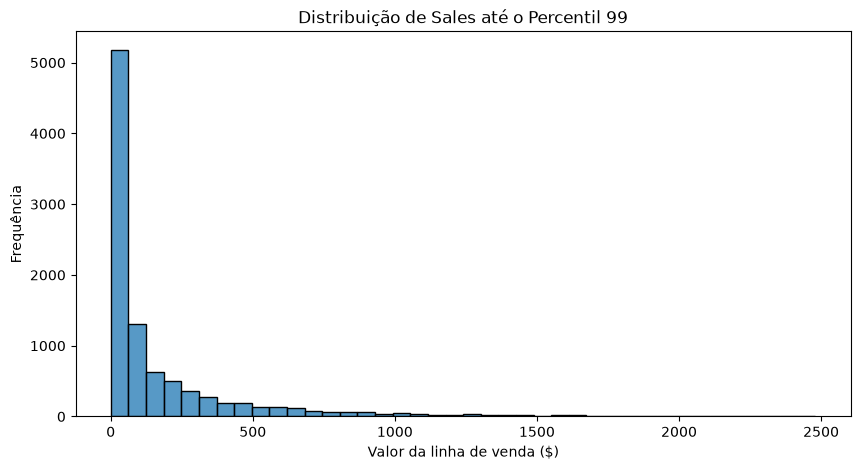

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=df[df["Sales"] <= sales_p99],
    x="Sales",
    bins=40,
    ax=ax
)

ax.set_title("Distribuição de Sales até o Percentil 99")
ax.set_xlabel("Valor da linha de venda ($)")
ax.set_ylabel("Frequência")

plt.show()

#### Interpretação da Distribuição

A distribuição de Sales apresenta forte assimetria à direita, com elevada concentração de linhas de venda nos valores mais baixos e redução progressiva da frequência à medida que os valores aumentam.

Esse comportamento é consistente com as estatísticas descritivas: a mediana de aproximadamente $54,48 é significativamente inferior à média de $230,76, indicando que valores elevados exercem influência relevante sobre a média.

Mesmo com a visualização limitada ao percentil 99, observa-se uma cauda superior longa. O 1% restante, que inclui valores ainda mais elevados, foi preservado no dataset e será investigado posteriormente na análise de valores atípicos.

Neste estágio, os valores elevados são tratados como observações extremas da distribuição, sem assumir que representam erros ou anomalias de qualidade.

### 2.3 — Distribuição do Valor dos Pedidos

Após analisar Sales no nível da linha de venda, a análise passa para o valor consolidado dos pedidos.

A questão exploratória desta etapa é:

> Como os valores totais dos pedidos estão distribuídos e em que medida pedidos de maior valor influenciam o ticket médio?

Para responder à questão, são avaliadas estatísticas descritivas e percentis de Order_Value, utilizando a tabela auxiliar orders, cuja granularidade corresponde a um registro por Order ID.

In [12]:
order_value_summary = orders["Order_Value"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

order_value_summary

count     4922.000000
mean       459.418003
std        958.666830
min          0.556000
25%         37.272000
50%        151.875000
75%        513.214000
90%       1158.415200
95%       1800.158100
99%       4206.356760
max      23661.228000
Name: Order_Value, dtype: float64

#### Visualização da Distribuição dos Pedidos

As estatísticas descritivas indicam que Order_Value também apresenta forte assimetria positiva. O ticket médio de aproximadamente $459,42 é significativamente superior à mediana de $151,88, sugerindo influência dos pedidos de maior valor sobre a média.

Para visualizar a região onde se concentra a maior parte dos pedidos, a distribuição é apresentada até o percentil 99. Os pedidos acima desse limite permanecem integralmente preservados na base e serão investigados posteriormente na análise de valores atípicos.

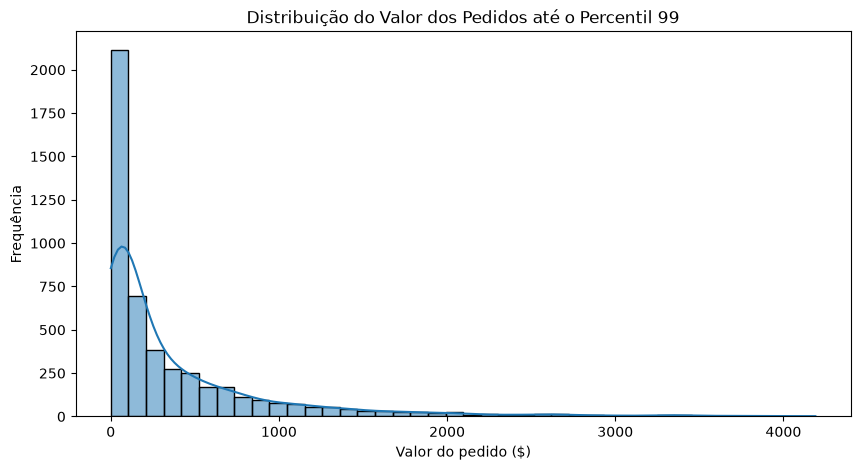

In [13]:
order_value_p99 = orders["Order_Value"].quantile(0.99)

fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=orders[orders["Order_Value"] <= order_value_p99],
    x="Order_Value",
    bins=40,
    kde=True,
    ax=ax
)

ax.set_title("Distribuição do Valor dos Pedidos até o Percentil 99")
ax.set_xlabel("Valor do pedido ($)")
ax.set_ylabel("Frequência")

plt.show()

#### Interpretação da Distribuição dos Pedidos

A distribuição de Order_Value apresenta forte assimetria à direita, com elevada concentração de pedidos nos menores valores e uma cauda superior longa.

A mediana de aproximadamente $151,88 é significativamente inferior ao ticket médio de $459,42, indicando que pedidos de maior valor exercem influência relevante sobre a média.

Cerca de 75% dos pedidos possuem valor de até $513,21, enquanto 95% permanecem abaixo de aproximadamente $1.800,16. No extremo superior, o percentil 99 é de aproximadamente $4.206,36, frente a um valor máximo de $23.661,23.

A curva KDE reforça visualmente a concentração dos pedidos na faixa inferior da distribuição e a redução progressiva da frequência conforme o valor do pedido aumenta.

Os pedidos de maior valor não são classificados neste momento como erros ou anomalias de negócio. Essas observações serão investigadas posteriormente na análise específica de valores atípicos.

## 3. Análise de Vendas por Dimensões

### 3.1 — Vendas por Categoria

In [14]:
category_sales = (
    df.groupby("Category", as_index=False)
      .agg(Revenue=("Sales", "sum"))
      .sort_values("Revenue", ascending=False)
)

category_sales["Revenue_Share"] = (
    category_sales["Revenue"] / category_sales["Revenue"].sum()
)

category_sales

,Category,Revenue,Revenue_Share
2,Technology,827455.8730,0.365928
0,Furniture,728377.2037,0.322112
1,Office Supplies,705422.3340,0.311960


#### Visualização da Receita por Categoria

A agregação inicial indica que as três categorias possuem participações relevantes na receita total, com liderança de Technology.

Para comparar diretamente a magnitude da receita entre as categorias, é utilizado um gráfico de barras ordenado de forma decrescente.

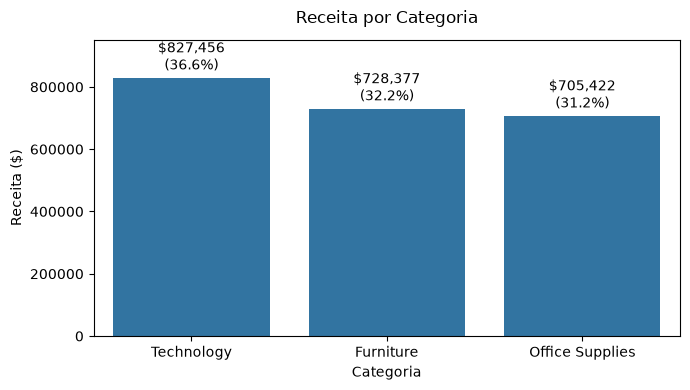

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))

sns.barplot(
    data=category_sales,
    x="Category",
    y="Revenue",
    ax=ax
)

labels = [
    f"${revenue:,.0f}\n({share:.1%})"
    for revenue, share in zip(
        category_sales["Revenue"],
        category_sales["Revenue_Share"]
    )
]

ax.bar_label(
    ax.containers[0],
    labels=labels,
    padding=3
)

ax.set_title("Receita por Categoria", pad=12)
ax.set_xlabel("Categoria")
ax.set_ylabel("Receita ($)")

ax.margins(y=0.15)

plt.tight_layout()
plt.show()

#### Interpretação das Vendas por Categoria

Technology apresenta a maior receita no período, com aproximadamente $827,46 mil, correspondendo a 36,6% da receita total.

Furniture representa 32,2% da receita, enquanto Office Supplies responde por 31,2%.

Apesar da liderança de Technology, a distribuição da receita entre as três categorias é relativamente equilibrada. Nenhuma categoria concentra mais de 40% do total, e a diferença entre a maior e a menor participação é de aproximadamente 5,4 pontos percentuais.

A análise não indica, portanto, dependência acentuada da receita em uma única categoria. O comportamento interno dessas categorias será aprofundado na análise por subcategoria.

### 3.2 — Vendas por Subcategoria

A análise por categoria apresentou uma distribuição relativamente equilibrada da receita entre os três grandes grupos de produtos.

Nesta etapa, a granularidade é aprofundada para Sub-Category, buscando responder à seguinte questão:

> A distribuição relativamente equilibrada observada entre as categorias também ocorre entre as subcategorias, ou a receita passa a apresentar maior concentração em determinados grupos de produtos?

Inicialmente, a receita é agregada por subcategoria e sua participação sobre a receita total é calculada. A ordenação decrescente permite identificar diferenças de magnitude e possíveis concentrações que não são visíveis no nível agregado de categoria.

In [16]:
subcategory_sales = (
    df.groupby(["Category", "Sub-Category"], as_index=False)
      .agg(Revenue=("Sales", "sum"))
      .sort_values("Revenue", ascending=False)
)

subcategory_sales["Revenue_Share"] = (
    subcategory_sales["Revenue"]
    / subcategory_sales["Revenue"].sum()
)

subcategory_sales

,Category,Sub-Category,Revenue,Revenue_Share
16,Technology,Phones,327782.4480,0.144956
1,Furniture,Chairs,322541.3590,0.142638
11,Office Supplies,Storage,219343.3920,0.097001
3,Furniture,Tables,202810.6280,0.089689
6,Office Supplies,Binders,200028.7850,0.088459
15,Technology,Machines,189238.6310,0.083687
13,Technology,Accessories,164186.7000,0.072609
14,Technology,Copiers,146248.0940,0.064676
0,Furniture,Bookcases,113813.1987,0.050332
4,Office Supplies,Appliances,104618.4030,0.046266


#### Visualização da Receita por Subcategoria

A agregação por subcategoria revela diferenças de magnitude mais expressivas do que aquelas observadas no nível de categoria.

Para preservar a legibilidade das 17 subcategorias e facilitar a comparação entre suas receitas, é utilizado um gráfico de barras horizontais ordenado de forma decrescente.

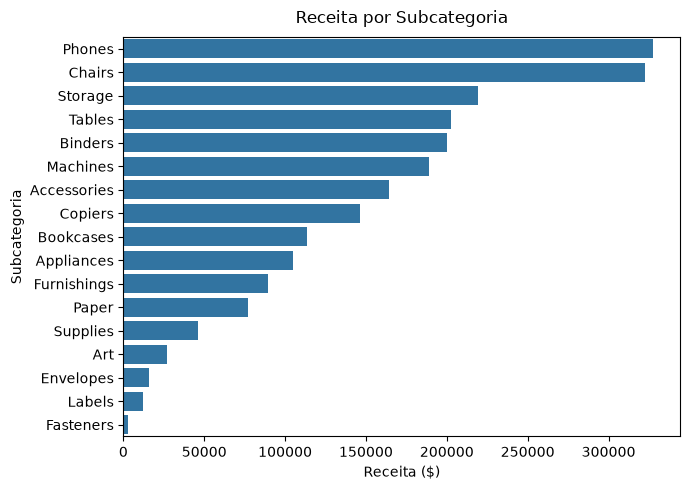

In [17]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.barplot(
    data=subcategory_sales,
    x="Revenue",
    y="Sub-Category",
    ax=ax
)

ax.set_title("Receita por Subcategoria", pad=10)
ax.set_xlabel("Receita ($)")
ax.set_ylabel("Subcategoria")

plt.tight_layout()
plt.show()

#### Análise de Concentração da Receita

Além da comparação individual entre as subcategorias, é avaliada a participação acumulada da receita.

Essa análise permite verificar quantas subcategorias são necessárias para representar aproximadamente 80% da receita total e identificar o grau de concentração do faturamento no portfólio de produtos.

#### Participação e Concentração da Receita

A tabela a seguir apresenta a receita por subcategoria, sua participação relativa na receita total e a participação acumulada.

Uma cópia da tabela analítica é utilizada exclusivamente para formatação e apresentação, preservando as variáveis numéricas originais para cálculos posteriores.

In [18]:
subcategory_sales = (
    df.groupby(["Category", "Sub-Category"], as_index=False)
      .agg(Revenue=("Sales", "sum"))
      .sort_values("Revenue", ascending=False)
)

subcategory_sales["Revenue_Share"] = (
    subcategory_sales["Revenue"] / subcategory_sales["Revenue"].sum()
)

subcategory_sales["Cumulative_Share"] = (
    subcategory_sales["Revenue_Share"].cumsum()
)

In [19]:
subcategory_frequency = subcategory_sales[
    ["Category", "Sub-Category", "Revenue", "Revenue_Share", "Cumulative_Share"]
].copy()

In [20]:
subcategory_frequency = subcategory_sales[
    ["Category", "Sub-Category", "Revenue", "Revenue_Share", "Cumulative_Share"]
].copy()

subcategory_frequency["Revenue"] = (
    subcategory_frequency["Revenue"]
    .map(lambda x: f"${x:,.2f}")
)

subcategory_frequency["Revenue_Share"] = (
    subcategory_frequency["Revenue_Share"]
    .map(lambda x: f"{x:.2%}")
)

subcategory_frequency["Cumulative_Share"] = (
    subcategory_frequency["Cumulative_Share"]
    .map(lambda x: f"{x:.2%}")
)

subcategory_frequency

,Category,Sub-Category,Revenue,Revenue_Share,Cumulative_Share
16,Technology,Phones,"$327,782.45",14.50%,14.50%
1,Furniture,Chairs,"$322,541.36",14.26%,28.76%
11,Office Supplies,Storage,"$219,343.39",9.70%,38.46%
3,Furniture,Tables,"$202,810.63",8.97%,47.43%
6,Office Supplies,Binders,"$200,028.79",8.85%,56.27%
15,Technology,Machines,"$189,238.63",8.37%,64.64%
13,Technology,Accessories,"$164,186.70",7.26%,71.90%
14,Technology,Copiers,"$146,248.09",6.47%,78.37%
0,Furniture,Bookcases,"$113,813.20",5.03%,83.40%
4,Office Supplies,Appliances,"$104,618.40",4.63%,88.03%


#### Interpretação das Vendas por Subcategoria

A análise por subcategoria revela maior heterogeneidade do que aquela observada no nível agregado de categoria.

Phones apresenta a maior receita, com aproximadamente $327,78 mil (14,5% do total), seguida de Chairs, com $322,54 mil (14,3%). Juntas, as duas subcategorias representam aproximadamente 28,8% da receita.

A participação acumulada demonstra que as oito primeiras subcategorias representam aproximadamente 78,4% da receita. O patamar de 80% é ultrapassado com a inclusão de Bookcases, quando as nove primeiras subcategorias passam a representar aproximadamente 83,4% do total.

Dessa forma, 9 das 17 subcategorias são necessárias para superar 80% da receita, indicando concentração moderada, mas não um padrão clássico de Pareto 80/20.

No extremo inferior, Fasteners, Labels e Envelopes apresentam participações individuais inferiores a 1% da receita total.

Os resultados mostram que o equilíbrio observado entre as três categorias principais não se mantém com a mesma intensidade quando a análise é aprofundada para o nível de subcategoria.

### 3.3 — Vendas por Segmento de Cliente

Após analisar a composição da receita por produto, a exploração passa para os segmentos de clientes.

A questão exploratória desta etapa é:

> Como a receita se distribui entre os segmentos de clientes e essa participação acompanha a quantidade de clientes e pedidos de cada segmento?

Para responder à questão, são comparadas a receita total, a quantidade de clientes distintos e a quantidade de pedidos distintos de cada segmento.

Essa abordagem permite avaliar se diferenças de receita estão associadas principalmente ao tamanho da base de clientes e ao volume de pedidos ou se existem sinais de diferenças no valor gerado por pedido.

In [21]:
segment_analysis = (
    df.groupby("Segment", as_index=False)
      .agg(
          Revenue=("Sales", "sum"),
          Customers=("Customer ID", "nunique"),
          Orders=("Order ID", "nunique")
      )
      .sort_values("Revenue", ascending=False)
)

segment_analysis["Revenue_Share"] = (
    segment_analysis["Revenue"]
    / segment_analysis["Revenue"].sum()
)

segment_analysis["Average_Order_Value"] = (
    segment_analysis["Revenue"]
    / segment_analysis["Orders"]
)

In [22]:
segment_analysis.style.format({
    "Revenue": "${:,.2f}",
    "Customers": "{:,.0f}",
    "Orders": "{:,.0f}",
    "Revenue_Share": "{:.2%}",
    "Average_Order_Value": "${:,.2f}"
})

,Segment,Revenue,Customers,Orders,Revenue_Share,Average_Order_Value
0,Consumer,"$1,148,060.53",409,"2,537",50.77%,$452.53
1,Corporate,"$688,494.07",236,"1,491",30.45%,$461.77
2,Home Office,"$424,700.80",148,894,18.78%,$475.06


#### Visualização da Receita por Segmento

A receita apresenta diferenças relevantes entre os três segmentos, com maior participação de Consumer.

Para visualizar a magnitude e a participação de cada segmento na receita total, é utilizado um gráfico de barras com os valores absolutos e percentuais. As métricas de clientes, pedidos e valor médio por pedido permanecem disponíveis na tabela analítica para complementar a interpretação.

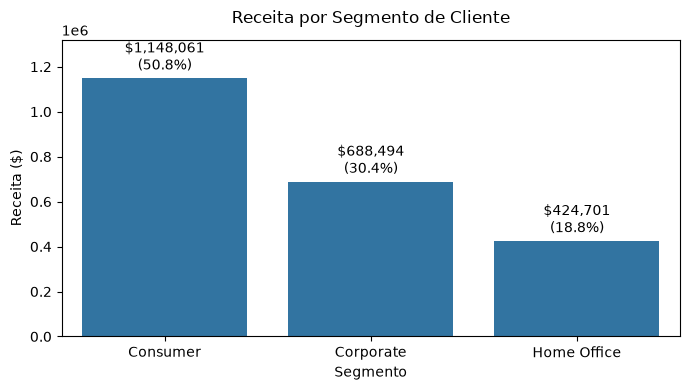

In [23]:
fig, ax = plt.subplots(figsize=(7, 4))

sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="Revenue",
    ax=ax
)

labels = [
    f"${revenue:,.0f}\n({share:.1%})"
    for revenue, share in zip(
        segment_analysis["Revenue"],
        segment_analysis["Revenue_Share"]
    )
]

ax.bar_label(
    ax.containers[0],
    labels=labels,
    padding=3
)

ax.set_title("Receita por Segmento de Cliente", pad=12)
ax.set_xlabel("Segmento")
ax.set_ylabel("Receita ($)")

ax.margins(y=0.15)

plt.tight_layout()
plt.show()

#### Interpretação das Vendas por Segmento de Cliente

O segmento Consumer apresenta a maior participação na receita, com aproximadamente $1,15 milhão, equivalente a 50,8% do faturamento total. Corporate representa 30,4%, enquanto Home Office responde pelos 18,8% restantes.

A liderança de Consumer também é acompanhada pelo maior número de clientes e pedidos: são 409 clientes e 2.537 pedidos, frente a 236 clientes e 1.491 pedidos em Corporate e 148 clientes e 894 pedidos em Home Office.

Entretanto, o valor médio por pedido apresenta pouca variação entre os segmentos. Consumer, apesar de liderar a receita, possui o menor ticket médio ($452,53), enquanto Corporate apresenta $461,77 e Home Office $475,06.

Esse resultado indica que a maior participação de Consumer na receita está associada principalmente ao maior volume de clientes e pedidos, e não a um valor médio por pedido significativamente superior.

A análise exploratória sugere, portanto, que o tamanho e a atividade da base de clientes exercem papel relevante na composição da receita entre os segmentos. O comportamento individual dos clientes será aprofundado posteriormente na análise específica de clientes.

### 3.4 — Vendas por Região

A última dimensão desta etapa da análise explora a distribuição geográfica da receita entre as regiões presentes no dataset.

A questão exploratória é:

> Como a receita está distribuída entre as regiões e existem diferenças relevantes na participação de cada uma no faturamento total?

Inicialmente, são avaliados a receita, a quantidade de clientes distintos, o número de pedidos e a participação de cada região na receita total. Essa visão permite verificar se a diferença regional está associada apenas ao volume de operações ou se também existem diferenças no valor médio dos pedidos.

In [24]:
region_analysis = (
    df.groupby("Region", as_index=False)
      .agg(
          Revenue=("Sales", "sum"),
          Customers=("Customer ID", "nunique"),
          Orders=("Order ID", "nunique")
      )
      .sort_values("Revenue", ascending=False)
)

region_analysis["Revenue_Share"] = (
    region_analysis["Revenue"]
    / region_analysis["Revenue"].sum()
)

region_analysis["Average_Order_Value"] = (
    region_analysis["Revenue"]
    / region_analysis["Orders"]
)

In [25]:
region_analysis.style.format({
    "Revenue": "${:,.2f}",
    "Customers": "{:,.0f}",
    "Orders": "{:,.0f}",
    "Revenue_Share": "{:.2%}",
    "Average_Order_Value": "${:,.2f}"
})

,Region,Revenue,Customers,Orders,Revenue_Share,Average_Order_Value
3,West,"$710,219.68",681,"1,587",31.41%,$447.52
1,East,"$669,237.35",669,"1,369",29.60%,$488.85
0,Central,"$492,646.91",626,"1,156",21.79%,$426.17
2,South,"$389,151.46",509,810,17.21%,$480.43


#### Visualização da Receita por Região

A comparação regional evidencia diferenças tanto na participação sobre a receita total quanto no volume de operações.

Para visualizar a magnitude da receita de cada região, é utilizado um gráfico de barras ordenado pela receita, apresentando simultaneamente os valores absolutos e suas respectivas participações percentuais.

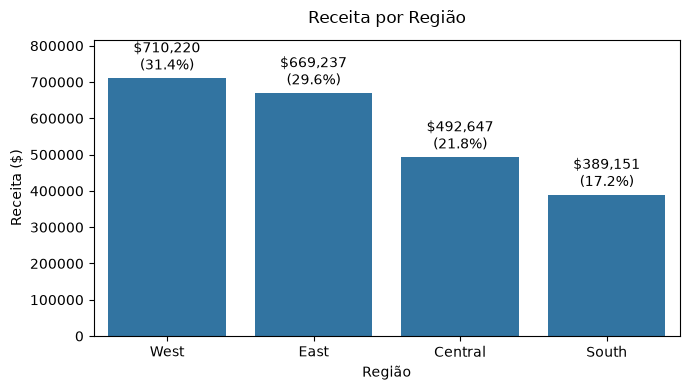

In [26]:
fig, ax = plt.subplots(figsize=(7, 4))

sns.barplot(
    data=region_analysis,
    x="Region",
    y="Revenue",
    ax=ax
)

labels = [
    f"${revenue:,.0f}\n({share:.1%})"
    for revenue, share in zip(
        region_analysis["Revenue"],
        region_analysis["Revenue_Share"]
    )
]

ax.bar_label(
    ax.containers[0],
    labels=labels,
    padding=3
)

ax.set_title("Receita por Região", pad=12)
ax.set_xlabel("Região")
ax.set_ylabel("Receita ($)")

ax.margins(y=0.15)

plt.tight_layout()
plt.show()

#### Interpretação das Vendas por Região

A distribuição regional da receita apresenta diferenças relevantes entre as quatro regiões analisadas.

West lidera o faturamento, com aproximadamente $710,22 mil, correspondendo a 31,4% da receita total. East aparece próxima, com $669,24 mil e participação de 29,6%. Juntas, as duas regiões representam aproximadamente 61,0% da receita.

Central responde por 21,8% do faturamento, enquanto South apresenta a menor participação, com 17,2%.

A análise do valor médio por pedido acrescenta uma perspectiva importante. Embora West apresente a maior receita total, East possui o maior ticket médio, aproximadamente $488,85. South, apesar de apresentar a menor receita e o menor número de pedidos, possui o segundo maior ticket médio, aproximadamente $480,43.

Central, por sua vez, apresenta o menor valor médio por pedido, aproximadamente $426,17.

Os resultados indicam que as diferenças de receita entre as regiões não são explicadas exclusivamente pelo valor médio dos pedidos. O volume de operações também exerce papel relevante na composição do faturamento regional.

Esses padrões serão aprofundados posteriormente nas análises especializadas, enquanto esta etapa exploratória estabelece a distribuição geográfica inicial da receita.

## 4. Análise Temporal Exploratória

A análise temporal busca compreender como a receita evoluiu ao longo do período disponível no dataset, identificando tendências, oscilações e possíveis padrões recorrentes.

Diferentemente das análises dimensionais anteriores, nesta etapa a ordem cronológica dos dados passa a ser parte essencial da análise.

### 4.1 — Evolução das Vendas

A primeira questão temporal investigada é:

> Como a receita evoluiu ao longo do período analisado e existem sinais iniciais de crescimento, queda ou mudanças relevantes no comportamento das vendas?

Para reduzir oscilações excessivamente granulares dos dados diários e preservar detalhes suficientes para identificar padrões ao longo do tempo, a receita será inicialmente analisada em frequência mensal.

Antes da visualização, a série temporal é construída e sua continuidade é validada, verificando se existem meses sem observações dentro do período analisado.

In [27]:
monthly_sales = (
    df.set_index("Order Date")
      .resample("MS")
      .agg(
          Revenue=("Sales", "sum"),
          Orders=("Order ID", "nunique")
      )
      .reset_index()
)

monthly_sales

,Order Date,Revenue,Orders
0,2015-01-01,14205.7070,30
1,2015-02-01,4519.8920,28
2,2015-03-01,55205.7970,69
3,2015-04-01,27625.4830,63
4,2015-05-01,23644.3030,68
5,2015-06-01,34322.9356,64
6,2015-07-01,33781.5430,64
7,2015-08-01,27117.5365,70
8,2015-09-01,81623.5268,129
9,2015-10-01,31453.3930,78


#### Validação da Continuidade Temporal

Antes de analisar a evolução da receita, é necessário verificar se a série mensal cobre continuamente todo o período observado.

A presença de meses ausentes poderia gerar interpretações incorretas sobre quedas de receita ou interrupções na atividade. Por isso, o número de meses observados é comparado com o calendário mensal esperado entre a primeira e a última data da série.

In [28]:
expected_months = pd.date_range(
    start=monthly_sales["Order Date"].min(),
    end=monthly_sales["Order Date"].max(),
    freq="MS"
)

observed_months = pd.DatetimeIndex(monthly_sales["Order Date"])

missing_months = expected_months.difference(observed_months)

print("Período inicial:", expected_months.min().strftime("%m/%Y"))
print("Período final:", expected_months.max().strftime("%m/%Y"))
print("Meses esperados:", len(expected_months))
print("Meses observados:", len(observed_months))
print("Meses ausentes:", len(missing_months))

if len(missing_months) > 0:
    print("\nMeses ausentes:")
    print(missing_months.strftime("%m/%Y").tolist())

Período inicial: 01/2015
Período final: 12/2018
Meses esperados: 48
Meses observados: 48
Meses ausentes: 0


#### Resultado da Validação Temporal

A série mensal cobre continuamente o período entre janeiro de 2015 e dezembro de 2018.

Foram identificados 48 meses esperados e 48 meses observados, sem períodos ausentes. Dessa forma, a série apresenta continuidade temporal adequada para a análise exploratória da evolução das vendas.

Essa validação reduz o risco de interpretar meses ausentes como quedas reais de receita.

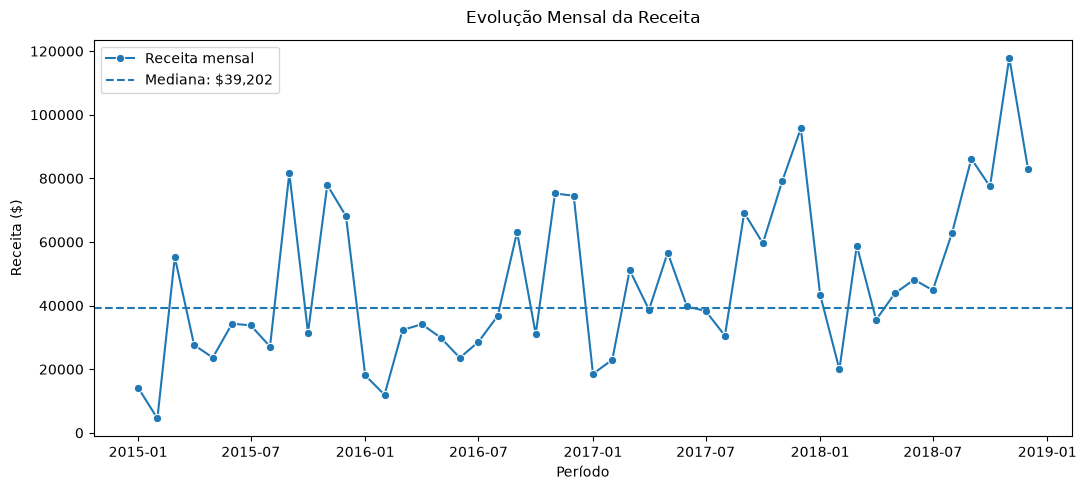

In [29]:
median_monthly_revenue = monthly_sales["Revenue"].median()

fig, ax = plt.subplots(figsize=(11, 5))

sns.lineplot(
    data=monthly_sales,
    x="Order Date",
    y="Revenue",
    marker="o",
    ax=ax,
    label="Receita mensal"
)

ax.axhline(
    y=median_monthly_revenue,
    linestyle="--",
    linewidth=1.5,
    label=f"Mediana: ${median_monthly_revenue:,.0f}"
)

ax.set_title("Evolução Mensal da Receita", pad=12)
ax.set_xlabel("Período")
ax.set_ylabel("Receita ($)")

ax.legend()

plt.tight_layout()
plt.show()

#### Interpretação da Evolução Mensal da Receita

A série mensal apresenta oscilações relevantes ao longo de todo o período analisado, com alternância entre meses de menor atividade e picos de receita.

A mediana da receita mensal no período é de aproximadamente $39,2 mil, funcionando como uma referência do nível central da série. Visualmente, observa-se maior frequência de meses acima dessa referência nos anos finais, especialmente em 2017 e 2018.

Apesar da variabilidade mensal, também se observa uma elevação aparente do nível de receita nos anos mais recentes. Os maiores valores mensais passam a ocorrer principalmente no final da série, incluindo o maior pico observado em novembro de 2018.

Além disso, alguns picos aparecem em períodos semelhantes de diferentes anos, especialmente nos últimos meses do calendário. Esse comportamento constitui um sinal inicial de possível padrão recorrente, mas ainda não é suficiente para caracterizar sazonalidade.

Dessa forma, a evolução mensal fornece duas hipóteses exploratórias principais: uma possível elevação da receita ao longo do tempo e uma possível recorrência de períodos de maior faturamento. Essas hipóteses serão avaliadas nas etapas seguintes da análise temporal.

### 4.2 — Comportamento Mensal

A evolução cronológica apresentou indícios de que determinados períodos do calendário podem concentrar níveis mais elevados de receita.

Nesta etapa, a dimensão temporal é reorganizada para comparar o comportamento dos mesmos meses ao longo dos diferentes anos.

A questão exploratória é:

> Existem meses que apresentam níveis de receita consistentemente mais elevados ou mais baixos quando comparados entre os diferentes anos?

Essa análise permite separar a posição do mês no calendário da sequência cronológica completa e constitui uma etapa intermediária para a investigação de possíveis padrões sazonais.

In [30]:
monthly_behavior = monthly_sales.copy()

monthly_behavior["Year"] = (
    monthly_behavior["Order Date"].dt.year
)

monthly_behavior["Month_Number"] = (
    monthly_behavior["Order Date"].dt.month
)

monthly_behavior["Month"] = (
    monthly_behavior["Order Date"].dt.strftime("%b")
)

monthly_behavior[
    ["Order Date", "Year", "Month_Number", "Month", "Revenue", "Orders"]
]

,Order Date,Year,Month_Number,Month,Revenue,Orders
0,2015-01-01,2015,1,Jan,14205.7070,30
1,2015-02-01,2015,2,Feb,4519.8920,28
2,2015-03-01,2015,3,Mar,55205.7970,69
3,2015-04-01,2015,4,Apr,27625.4830,63
4,2015-05-01,2015,5,May,23644.3030,68
5,2015-06-01,2015,6,Jun,34322.9356,64
6,2015-07-01,2015,7,Jul,33781.5430,64
7,2015-08-01,2015,8,Aug,27117.5365,70
8,2015-09-01,2015,9,Sep,81623.5268,129
9,2015-10-01,2015,10,Oct,31453.3930,78


#### Comparação da Receita Mensal entre os Anos

Para facilitar a comparação entre os mesmos meses nos diferentes anos, a série é reorganizada em uma matriz na qual cada linha representa um mês do calendário e cada coluna representa um ano.

Essa estrutura permite observar se os períodos de maior ou menor receita se repetem ao longo dos anos, sem perder as diferenças de magnitude existentes entre eles.

In [31]:
monthly_comparison = (
    monthly_behavior
    .pivot(
        index=["Month_Number", "Month"],
        columns="Year",
        values="Revenue"
    )
    .reset_index()
    .sort_values("Month_Number")
)

monthly_comparison

Year,Month_Number,Month,2015,2016,2017,2018
0,1,Jan,14205.7070,18066.9576,18542.4910,43476.4740
1,2,Feb,4519.8920,11951.4110,22978.8150,19920.9974
2,3,Mar,55205.7970,32339.3184,51165.0590,58863.4128
3,4,Apr,27625.4830,34154.4685,38679.7670,35541.9101
4,5,May,23644.3030,29959.5305,56656.9080,43825.9822
5,6,Jun,34322.9356,23599.3740,39724.4860,48190.7277
6,7,Jul,33781.5430,28608.2590,38320.7830,44825.1040
7,8,Aug,27117.5365,36818.3422,30542.2003,62837.8480
8,9,Sep,81623.5268,63133.6060,69193.3909,86152.8880
9,10,Oct,31453.3930,31011.7375,59583.0330,77448.1312


#### Receita Típica por Mês do Calendário

Além da comparação direta entre os anos, é calculada a mediana da receita de cada mês do calendário.

A mediana fornece uma referência do comportamento típico de cada mês considerando os quatro anos disponíveis, reduzindo a influência de valores particularmente elevados ou baixos em um único ano.

Essa medida auxilia na identificação de meses que apresentam níveis de receita consistentemente mais altos ou mais baixos ao longo do período analisado.

In [32]:
monthly_median = (
    monthly_behavior
    .groupby(["Month_Number", "Month"], as_index=False)
    .agg(
        Median_Revenue=("Revenue", "median")
    )
    .sort_values("Month_Number")
)

monthly_median.style.format({
    "Median_Revenue": "${:,.2f}"
})

,Month_Number,Month,Median_Revenue
0,1,Jan,"$18,304.72"
1,2,Feb,"$15,936.20"
2,3,Mar,"$53,185.43"
3,4,Apr,"$34,848.19"
4,5,May,"$36,892.76"
5,6,Jun,"$37,023.71"
6,7,Jul,"$36,051.16"
7,8,Aug,"$33,680.27"
8,9,Sep,"$75,408.46"
9,10,Oct,"$45,518.21"


#### Visualização da Receita Mediana por Mês

A mediana mensal permite comparar o nível típico de receita de cada mês do calendário considerando os quatro anos disponíveis.

O gráfico a seguir apresenta essas medianas em ordem cronológica, preservando a sequência de janeiro a dezembro e facilitando a identificação de períodos que apresentam níveis de receita tipicamente mais elevados ou mais baixos.

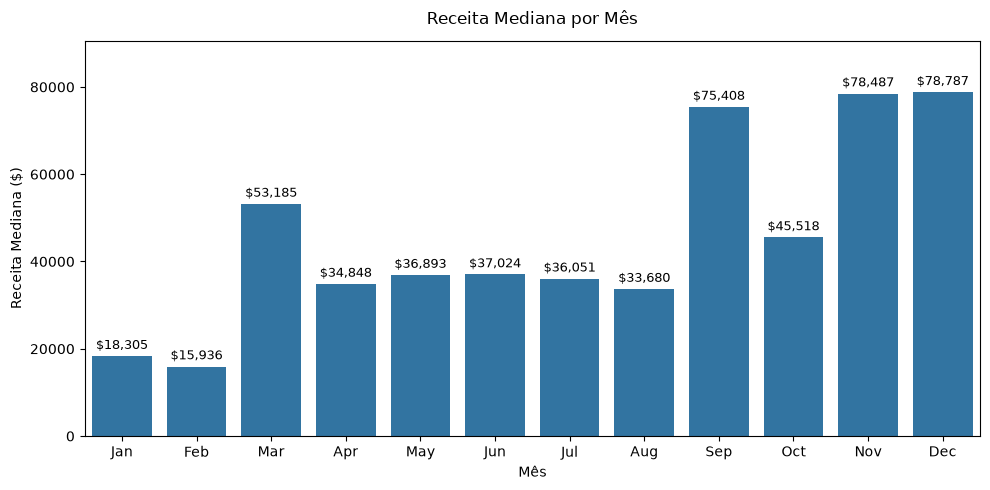

In [33]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=monthly_median,
    x="Month",
    y="Median_Revenue",
    ax=ax
)

ax.bar_label(
    ax.containers[0],
    labels=[
        f"${value:,.0f}"
        for value in monthly_median["Median_Revenue"]
    ],
    padding=3,
    fontsize=9
)

ax.set_title("Receita Mediana por Mês", pad=12)
ax.set_xlabel("Mês")
ax.set_ylabel("Receita Mediana ($)")

ax.margins(y=0.15)

plt.tight_layout()
plt.show()

#### Interpretação do Comportamento Mensal

A comparação das medianas mensais evidencia diferenças relevantes no nível típico de receita ao longo do calendário.

Janeiro e Fevereiro apresentam as menores medianas, aproximadamente $18,3 mil e $15,9 mil, respectivamente. Entre Março e Agosto, a receita permanece predominantemente em um patamar intermediário, embora Março se destaque com mediana de aproximadamente $53,2 mil.

A partir de Setembro, observa-se uma mudança importante no comportamento. Setembro apresenta mediana de aproximadamente $75,4 mil, enquanto Novembro e Dezembro atingem cerca de $78,5 mil e $78,8 mil, respectivamente. Outubro, entretanto, apresenta valor inferior aos demais meses desse período, com aproximadamente $45,5 mil.

Esses resultados reforçam a hipótese levantada na análise cronológica de que determinados períodos do calendário apresentam níveis de receita sistematicamente diferentes.

Entretanto, as medianas representam apenas quatro observações para cada mês do calendário. Portanto, o padrão identificado deve ser tratado como evidência exploratória de possível sazonalidade, e não como confirmação definitiva de um efeito sazonal.

### 4.3 — Sazonalidade Inicial

As análises anteriores indicaram que determinados meses do calendário apresentam níveis de receita distintos, com valores tipicamente mais elevados em períodos como setembro, novembro e dezembro.

Entretanto, diferenças entre medianas mensais não são suficientes, isoladamente, para caracterizar um comportamento sazonal. Para investigar a recorrência do padrão, é necessário observar se meses semelhantes assumem posições relativamente altas ou baixas dentro de diferentes anos.

A questão exploratória desta etapa é:

> Os períodos de maior e menor receita apresentam recorrência entre os anos analisados, indicando um possível componente sazonal?

Como o dataset contém quatro ciclos anuais completos, esta análise será utilizada como evidência exploratória de recorrência, sem tratar o padrão observado como confirmação estatística definitiva de sazonalidade.

In [34]:
annual_monthly_reference = (
    monthly_behavior
    .groupby("Year", as_index=False)
    .agg(
        Annual_Monthly_Mean=("Revenue", "mean")
    )
)

seasonality_analysis = monthly_behavior.merge(
    annual_monthly_reference,
    on="Year",
    how="left"
)

seasonality_analysis["Seasonal_Index"] = (
    seasonality_analysis["Revenue"]
    / seasonality_analysis["Annual_Monthly_Mean"]
)

seasonality_analysis[
    [
        "Year",
        "Month_Number",
        "Month",
        "Revenue",
        "Annual_Monthly_Mean",
        "Seasonal_Index"
    ]
]

,Year,Month_Number,Month,Revenue,Annual_Monthly_Mean,Seasonal_Index
0,2015,1,Jan,14205.7070,39964.569675,0.355458
1,2015,2,Feb,4519.8920,39964.569675,0.113097
2,2015,3,Mar,55205.7970,39964.569675,1.381368
3,2015,4,Apr,27625.4830,39964.569675,0.691249
4,2015,5,May,23644.3030,39964.569675,0.591632
5,2015,6,Jun,34322.9356,39964.569675,0.858834
6,2015,7,Jul,33781.5430,39964.569675,0.845287
7,2015,8,Aug,27117.5365,39964.569675,0.678539
8,2015,9,Sep,81623.5268,39964.569675,2.042397
9,2015,10,Oct,31453.3930,39964.569675,0.787032


#### Recorrência do Comportamento Mensal

Após normalizar a receita mensal pelo nível médio de cada ano, é possível avaliar a recorrência do comportamento de cada mês independentemente das diferenças de escala entre os anos.

Para cada mês do calendário, são calculados o índice sazonal mediano e a quantidade de anos em que a receita ficou acima da média mensal do respectivo ano.

Essa combinação permite distinguir meses que apresentam apenas valores pontualmente elevados daqueles cujo comportamento relativo se repete ao longo dos diferentes ciclos anuais.

In [35]:
seasonality_summary = (
    seasonality_analysis
    .groupby(["Month_Number", "Month"], as_index=False)
    .agg(
        Median_Seasonal_Index=("Seasonal_Index", "median"),
        Min_Seasonal_Index=("Seasonal_Index", "min"),
        Max_Seasonal_Index=("Seasonal_Index", "max"),
        Years_Above_Average=(
            "Seasonal_Index",
            lambda x: (x > 1).sum()
        )
    )
    .sort_values("Month_Number")
)

seasonality_summary.style.format({
    "Median_Seasonal_Index": "{:.2f}",
    "Min_Seasonal_Index": "{:.2f}",
    "Max_Seasonal_Index": "{:.2f}",
    "Years_Above_Average": "{:.0f}"
})

,Month_Number,Month,Median_Seasonal_Index,Min_Seasonal_Index,Max_Seasonal_Index,Years_Above_Average
0,1,Jan,0.42,0.36,0.72,0
1,2,Feb,0.32,0.11,0.46,0
2,3,Mar,1.00,0.84,1.38,2
3,4,Apr,0.73,0.59,0.89,0
4,5,May,0.76,0.59,1.13,1
5,6,Jun,0.80,0.62,0.86,0
6,7,Jul,0.76,0.74,0.85,0
7,8,Aug,0.82,0.61,1.04,1
8,9,Sep,1.54,1.38,2.04,4
9,10,Oct,1.00,0.79,1.29,2


#### Visualização da Recorrência Sazonal

Para visualizar a recorrência do comportamento mensal entre os diferentes anos, os índices relativos são organizados em uma matriz de mês por ano.

Valores superiores a 1,00 representam meses com receita acima da média mensal do respectivo ano, enquanto valores inferiores a 1,00 representam meses abaixo dessa referência.

O objetivo da visualização é identificar se posições relativas semelhantes se repetem nos diferentes ciclos anuais, reduzindo a influência do crescimento do nível geral de receita ao longo do período.

In [36]:
seasonality_matrix = (
    seasonality_analysis
    .pivot(
        index="Month",
        columns="Year",
        values="Seasonal_Index"
    )
    .reindex(monthly_median["Month"])
)

seasonality_matrix

Year,2015,2016,2017,2018
Month,,,,
Jan,0.355458,0.471891,0.370731,0.722549
Feb,0.113097,0.312159,0.459429,0.331073
Mar,1.381368,0.844670,1.022973,0.978269
Apr,0.691249,0.892080,0.773347,0.590682
May,0.591632,0.782512,1.132775,0.728357
Jun,0.858834,0.616392,0.794235,0.800896
Jul,0.845287,0.747219,0.766170,0.744962
Aug,0.678539,0.961658,0.610648,1.044321
Sep,2.042397,1.648985,1.383424,1.431801


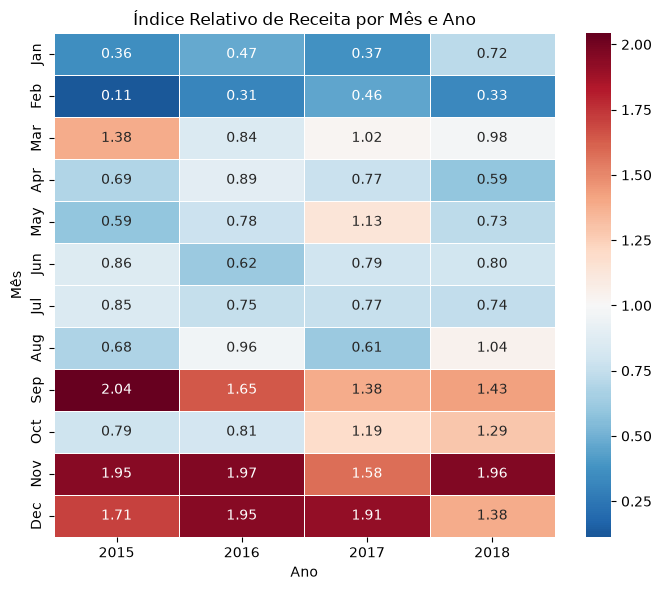

In [37]:
fig, ax = plt.subplots(figsize=(7, 6))

sns.heatmap(
    seasonality_matrix,
    annot=True,
    fmt=".2f",
    center=1,
    cmap="RdBu_r",
    linewidths=0.5,
    ax=ax
)

ax.set_title("Índice Relativo de Receita por Mês e Ano", pad=6)
ax.set_xlabel("Ano")
ax.set_ylabel("Mês")

plt.tight_layout()
plt.show()

#### Interpretação da Sazonalidade Inicial

A normalização da receita mensal pelo nível médio de cada ano evidencia padrões recorrentes ao longo dos quatro ciclos anuais analisados.

Setembro, Novembro e Dezembro apresentam índices superiores a 1,00 em todos os anos, indicando que esses meses permaneceram acima da média mensal de seus respectivos anos. Entre eles, Novembro apresenta o comportamento mais consistente, com índice sazonal mediano de aproximadamente 1,95.

Em sentido oposto, Janeiro, Fevereiro, Abril, Junho e Julho permaneceram abaixo da média mensal em todos os quatro anos. Fevereiro apresenta o menor índice sazonal mediano, aproximadamente 0,32, caracterizando o período de menor nível relativo de receita entre os meses analisados.

Outros meses apresentam comportamento menos consistente. Março e Outubro, por exemplo, ficaram acima da média em apenas dois dos quatro anos, enquanto Maio e Agosto superaram essa referência em apenas um ano.

O conjunto das evidências — comparação mensal, índices normalizados, recorrência entre os anos e heatmap — indica a presença de um possível componente sazonal na receita, com maior intensidade relativa principalmente em setembro, novembro e dezembro.

Entretanto, como a análise contempla apenas quatro ciclos anuais, os resultados devem ser interpretados como evidência exploratória de sazonalidade, e não como confirmação estatística definitiva. Uma investigação temporal mais aprofundada poderá ser realizada posteriormente no notebook específico de séries temporais e forecasting.

## 5. Distribuições e Valores Atípicos

Após analisar o comportamento geral, dimensional e temporal da receita, esta seção aprofunda a estrutura das distribuições presentes nos dados.

O objetivo é compreender a dispersão, assimetria e presença de valores extremos, distinguindo observações estatisticamente atípicas de possíveis problemas de qualidade dos dados.

### 5.1 — Distribuição de Sales

A análise inicial demonstrou que Sales apresenta forte assimetria à direita, com diferença relevante entre média e mediana e presença de valores muito superiores à maior parte das observações.

Nesta etapa, a distribuição será investigada por meio dos quartis e do intervalo interquartil (IQR), permitindo estabelecer limites estatísticos para identificação de observações potencialmente atípicas.

A questão exploratória é:

> Qual é a amplitude da região central da distribuição de Sales e quantas observações se encontram além dos limites definidos pelo critério do IQR?

A classificação estatística de uma observação como outlier não implica, por si só, erro ou anomalia de negócio. Os valores identificados serão posteriormente investigados antes de qualquer conclusão.

In [38]:
from src.metrics import calculate_iqr_bounds

In [39]:
sales_iqr = calculate_iqr_bounds(df["Sales"])

In [40]:
sales_iqr_table = pd.DataFrame({
    "Métrica": [
        "Q1",
        "Mediana",
        "Q3",
        "IQR",
        "Limite Inferior",
        "Limite Superior"
    ],
    "Valor": [
        sales_iqr["q1"],
        sales_iqr["median"],
        sales_iqr["q3"],
        sales_iqr["iqr"],
        sales_iqr["lower_bound"],
        sales_iqr["upper_bound"]
    ]
})

sales_iqr_table.style.format({
    "Valor": "${:,.2f}"
})

,Métrica,Valor
0,Q1,$17.25
1,Mediana,$54.48
2,Q3,$210.57
3,IQR,$193.32
4,Limite Inferior,$-272.74
5,Limite Superior,$500.56


#### Quantificação das Observações Além dos Limites do IQR

Com os limites estatísticos definidos, o próximo passo é identificar quantas observações de Sales se encontram fora da região estabelecida pelo critério de 1,5 × IQR.

Além da quantidade absoluta, é calculada a proporção dessas observações em relação ao total de registros e sua distribuição entre os limites inferior e superior.

Essa etapa permite dimensionar a presença de valores estatisticamente atípicos antes de investigá-los individualmente.

In [41]:
lower_outliers = df[
    df["Sales"] < sales_iqr["lower_bound"]
]

upper_outliers = df[
    df["Sales"] > sales_iqr["upper_bound"]
]

sales_outliers = df[
    (df["Sales"] < sales_iqr["lower_bound"])
    | (df["Sales"] > sales_iqr["upper_bound"])
]

outlier_percentage = (
    len(sales_outliers) / len(df) * 100
)

print(f"Total de registros: {len(df):,}")
print(f"Outliers inferiores: {len(lower_outliers):,}")
print(f"Outliers superiores: {len(upper_outliers):,}")
print(f"Total de outliers: {len(sales_outliers):,}")
print(f"Percentual de outliers: {outlier_percentage:.2f}%")

Total de registros: 9,799
Outliers inferiores: 0
Outliers superiores: 1,145
Total de outliers: 1,145
Percentual de outliers: 11.68%


#### Visualização da Distribuição pelo Boxplot

O boxplot permite representar visualmente a região central da distribuição de Sales, seus quartis, mediana, limites dos whiskers e observações localizadas além desses limites.

Como a distribuição apresenta forte assimetria à direita, espera-se uma concentração da caixa nos valores mais baixos e uma quantidade relevante de observações acima do limite superior.

Os pontos além dos whiskers representam observações estatisticamente atípicas segundo o critério do IQR, não necessariamente erros nos dados.

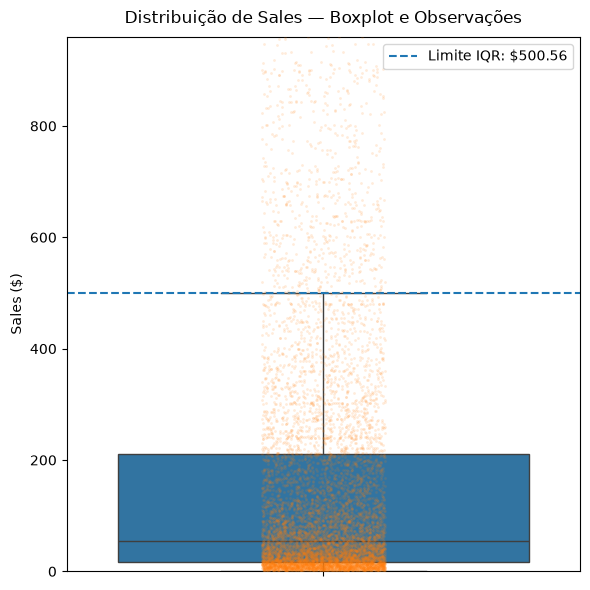

In [42]:
p95_sales = df["Sales"].quantile(0.95)

fig, ax = plt.subplots(figsize=(6, 6))

sns.boxplot(
    data=df,
    y="Sales",
    showfliers=False,
    ax=ax
)

sns.stripplot(
    data=df[df["Sales"] <= p95_sales],
    y="Sales",
    size=2,
    alpha=0.15,
    jitter=0.12,
    ax=ax
)

ax.axhline(
    sales_iqr["upper_bound"],
    linestyle="--",
    linewidth=1.5,
    label=f"Limite IQR: ${sales_iqr['upper_bound']:,.2f}"
)

ax.set_ylim(0, p95_sales)

ax.set_title("Distribuição de Sales — Boxplot e Observações", pad=10)
ax.set_xlabel("")
ax.set_ylabel("Sales ($)")
ax.legend()

plt.tight_layout()
plt.show()

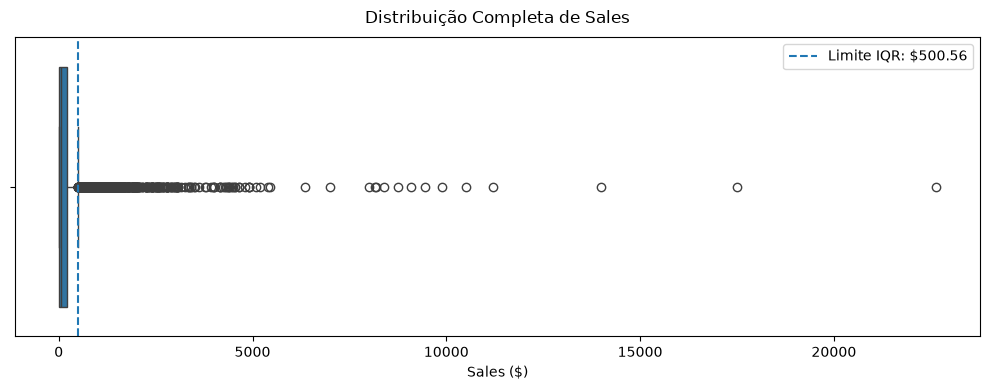

In [43]:
fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="Sales",
    ax=ax
)

ax.axvline(
    sales_iqr["upper_bound"],
    linestyle="--",
    linewidth=1.5,
    label=f"Limite IQR: ${sales_iqr['upper_bound']:,.2f}"
)

ax.set_title("Distribuição Completa de Sales", pad=10)
ax.set_xlabel("Sales ($)")
ax.legend()

plt.tight_layout()
plt.show()

#### Visualização da Distribuição pelo Boxplot

A distribuição de Sales é apresentada sob duas perspectivas complementares.

O primeiro boxplot preserva toda a amplitude dos dados, permitindo visualizar a extensão da cauda direita e a presença de observações muito superiores à região central da distribuição.

Como esses valores extremos comprimem visualmente os quartis e a mediana, a segunda visualização amplia a região até o percentil 95 e sobrepõe as observações individuais ao boxplot. Essa combinação permite observar simultaneamente a estrutura resumida da distribuição e a concentração dos registros ao longo dos diferentes níveis de Sales.

O recorte até o percentil 95 é exclusivamente visual: nenhuma observação é removida dos cálculos estatísticos, e os quartis e limites do IQR continuam sendo determinados a partir do conjunto completo de dados.

Em conjunto, as duas perspectivas permitem observar tanto a magnitude da cauda extrema quanto a estrutura central e a densidade das observações na maior parte da distribuição.

#### Impacto dos Valores Atípicos na Receita

A identificação de 1.145 observações acima do limite superior do IQR demonstra que aproximadamente 11,68% das linhas de venda são classificadas como estatisticamente atípicas pelo critério adotado.

Entretanto, a frequência dessas observações não informa, isoladamente, sua relevância financeira. Como os valores estão concentrados na cauda superior da distribuição, é necessário avaliar quanto da receita total está associado a esse grupo.

A questão investigada nesta etapa é:

> Qual é a participação dos valores classificados como outliers na receita total e qual é sua magnitude em comparação com as demais observações?

Essa análise ajuda a distinguir valores estatisticamente extremos de observações economicamente relevantes que fazem parte do comportamento real das vendas.

In [44]:
upper_outliers = df[
    df["Sales"] > sales_iqr["upper_bound"]
].copy()

outlier_revenue = upper_outliers["Sales"].sum()

non_outlier_revenue = (
    df["Sales"].sum() - outlier_revenue
)

outlier_revenue_share = (
    outlier_revenue / df["Sales"].sum()
)

In [45]:
outlier_impact = pd.DataFrame({
    "Grupo": [
        "Outliers superiores",
        "Demais observações"
    ],
    "Registros": [
        len(upper_outliers),
        len(df) - len(upper_outliers)
    ],
    "Participação nos Registros": [
        len(upper_outliers) / len(df),
        (len(df) - len(upper_outliers)) / len(df)
    ],
    "Receita": [
        outlier_revenue,
        non_outlier_revenue
    ],
    "Participação na Receita": [
        outlier_revenue_share,
        1 - outlier_revenue_share
    ]
})

outlier_impact.style.format({
    "Registros": "{:,.0f}",
    "Participação nos Registros": "{:.2%}",
    "Receita": "${:,.2f}",
    "Participação na Receita": "{:.2%}"
})

,Grupo,Registros,Participação nos Registros,Receita,Participação na Receita
0,Outliers superiores,"1,145",11.68%,"$1,454,775.41",64.33%
1,Demais observações,"8,654",88.32%,"$806,480.00",35.67%


#### Magnitude dos Outliers Superiores

A elevada participação dos outliers na receita indica que essas observações não devem ser tratadas automaticamente como registros descartáveis.

Para compreender melhor esse grupo, são analisadas medidas de posição e dispersão dos valores classificados acima do limite superior do IQR, permitindo avaliar sua magnitude e a heterogeneidade existente dentro da própria cauda da distribuição.

In [46]:
outlier_profile = (
    upper_outliers["Sales"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame(name="Valor")
)

def format_outlier_profile(value, row_name):
    if row_name == "count":
        return f"{value:,.0f}"
    return f"${value:,.2f}"

outlier_profile.style.format(
    lambda value: f"${value:,.2f}",
    subset=pd.IndexSlice[
        outlier_profile.index != "count",
        "Valor"
    ]
).format(
    "{:,.0f}",
    subset=pd.IndexSlice[["count"], ["Valor"]]
)

,Valor
count,"1,145"
mean,"$1,270.55"
std,"$1,427.90"
min,$501.81
25%,$636.86
50%,$871.40
75%,"$1,348.70"
90%,"$2,267.06"
95%,"$3,059.98"
99%,"$8,089.56"


#### Inspeção das Maiores Observações

A distribuição dos outliers demonstra que o próprio grupo apresenta elevada heterogeneidade, com valores próximos ao limite do IQR e uma cauda significativamente mais extrema.

Para avaliar se os maiores registros apresentam características plausíveis do ponto de vista do negócio, são inspecionadas as observações de maior valor juntamente com seus principais atributos comerciais.

Essa inspeção não busca eliminar automaticamente os maiores valores, mas identificar possíveis padrões ou sinais que justifiquem investigação adicional.

In [47]:
top_sales = (
    df[
        [
            "Order ID",
            "Order Date",
            "Customer ID",
            "Segment",
            "Region",
            "Category",
            "Sub-Category",
            "Product Name",
            "Sales"
        ]
    ]
    .sort_values("Sales", ascending=False)
    .head(10)
)

top_sales.style.format({
    "Order Date": lambda x: x.strftime("%d/%m/%Y"),
    "Sales": "${:,.2f}"
})

,Order ID,Order Date,Customer ID,Segment,Region,Category,Sub-Category,Product Name,Sales
5937,CA-2015-145317,18/03/2015,SM-20320,Home Office,South,Technology,Machines,Cisco TelePresence System EX90 Videoconferencing Unit,"$22,638.48"
6033,CA-2017-118689,02/10/2017,TC-20980,Corporate,Central,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,"$17,499.95"
6042,CA-2018-140151,23/03/2018,RB-19360,Consumer,West,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,"$13,999.96"
6008,CA-2018-127180,22/10/2018,TA-21385,Home Office,East,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,"$11,199.97"
6016,CA-2018-166709,17/11/2018,HL-15040,Consumer,East,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,"$10,499.97"
761,CA-2017-117121,17/12/2017,AB-10105,Consumer,Central,Office Supplies,Binders,GBC Ibimaster 500 Manual ProClick Binding System,"$9,892.74"
582,CA-2015-116904,23/09/2015,SC-20095,Consumer,Central,Office Supplies,Binders,Ibico EPK-21 Electric Binding System,"$9,449.95"
5954,US-2017-107440,16/04/2017,BS-11365,Corporate,East,Technology,Machines,"3D Systems Cube Printer, 2nd Generation, Magenta","$9,099.93"
5989,CA-2017-158841,02/02/2017,SE-20110,Consumer,South,Technology,Machines,"HP Designjet T520 Inkjet Large Format Printer - 24"" Color","$8,749.95"
6030,CA-2017-143714,23/05/2017,CC-12370,Consumer,East,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,"$8,399.98"


#### Composição dos Outliers por Categoria e Subcategoria

A inspeção das maiores observações sugere concentração em produtos de maior valor, especialmente nas categorias relacionadas à tecnologia.

Para verificar se esse comportamento se restringe aos casos mais extremos ou caracteriza o conjunto completo dos outliers superiores, sua composição é analisada por categoria e subcategoria.

Essa etapa permite avaliar quais grupos de produtos contribuem com maior frequência e receita para a cauda superior da distribuição.

In [48]:
outlier_composition = (
    upper_outliers
    .groupby(["Category", "Sub-Category"], as_index=False)
    .agg(
        Outlier_Records=("Sales", "size"),
        Outlier_Revenue=("Sales", "sum")
    )
    .sort_values("Outlier_Revenue", ascending=False)
)

outlier_composition["Record_Share"] = (
    outlier_composition["Outlier_Records"]
    / len(upper_outliers)
)

outlier_composition["Revenue_Share"] = (
    outlier_composition["Outlier_Revenue"]
    / outlier_revenue
)

outlier_composition.style.format({
    "Outlier_Records": "{:,.0f}",
    "Outlier_Revenue": "${:,.2f}",
    "Record_Share": "{:.2%}",
    "Revenue_Share": "{:.2%}"
})

,Category,Sub-Category,Outlier_Records,Outlier_Revenue,Record_Share,Revenue_Share
1,Furniture,Chairs,222,"$231,278.19",19.39%,15.90%
15,Technology,Phones,208,"$211,422.36",18.17%,14.53%
14,Technology,Machines,65,"$176,773.31",5.68%,12.15%
3,Furniture,Tables,145,"$158,734.80",12.66%,10.91%
13,Technology,Copiers,55,"$141,388.26",4.80%,9.72%
6,Office Supplies,Binders,78,"$140,576.60",6.81%,9.66%
10,Office Supplies,Storage,138,"$125,687.91",12.05%,8.64%
0,Furniture,Bookcases,62,"$73,643.63",5.41%,5.06%
12,Technology,Accessories,66,"$72,459.76",5.76%,4.98%
4,Office Supplies,Appliances,54,"$57,897.67",4.72%,3.98%


#### Interpretação

A análise confirma que Sales apresenta uma distribuição fortemente assimétrica à direita, caracterizada por grande concentração de observações em valores relativamente baixos e uma cauda superior extensa.

Pelo critério do intervalo interquartil (IQR), foram identificadas 1.145 observações acima do limite superior de $500,56, correspondendo a 11,68% dos registros. Apesar de representarem uma parcela minoritária das linhas de venda, essas observações concentram 64,33% da receita total, evidenciando elevada relevância econômica da cauda superior da distribuição.

O próprio conjunto de outliers também apresenta forte heterogeneidade. Sua mediana é de $871,40, enquanto o percentil 99 alcança $8.089,56 e o valor máximo chega a $22.638,48, indicando que uma pequena parcela dos próprios outliers possui magnitude substancialmente superior às demais observações desse grupo.

A inspeção dos maiores registros demonstra presença recorrente de produtos de alto valor, especialmente em Technology, com destaque para Copiers e Machines. Entretanto, a análise do conjunto completo dos outliers mostra uma composição mais diversificada: Chairs e Phones apresentam as maiores participações em quantidade de registros, enquanto subcategorias como Machines e Copiers combinam menor frequência com participação relevante na receita dos outliers.

Dessa forma, os valores classificados como outliers pelo critério estatístico não apresentam, nesta etapa, evidência suficiente para serem tratados automaticamente como erros ou removidos da análise. Ao contrário, constituem uma parcela economicamente relevante da distribuição e refletem diferenças importantes na magnitude das vendas entre produtos e subcategorias.

A composição e o comportamento desses grupos serão aprofundados posteriormente nas análises especializadas de vendas e produtos.

### 5.2 — Distribuição do Valor por Pedido

A análise anterior avaliou a distribuição de Sales na granularidade das linhas de venda. Entretanto, um mesmo pedido pode conter múltiplos itens, fazendo com que o valor de uma linha não represente necessariamente o valor econômico total de uma transação.

Nesta etapa, a unidade de análise passa a ser o pedido consolidado, utilizando a variável Order_Value, calculada pela soma de Sales para cada Order ID.

A questão exploratória é:

> Como os valores totais dos pedidos estão distribuídos e qual é a presença de pedidos estatisticamente atípicos nessa distribuição?

A análise permitirá comparar o comportamento observado no nível das linhas de venda com a distribuição das transações completas, evitando confundir valores elevados de itens individuais com pedidos de elevado valor total.

In [49]:
order_iqr = calculate_iqr_bounds(orders["Order_Value"])

In [50]:
order_iqr_table = pd.DataFrame({
    "Métrica": [
        "Q1",
        "Mediana",
        "Q3",
        "IQR",
        "Limite Inferior",
        "Limite Superior"
    ],
    "Valor": [
        order_iqr["q1"],
        order_iqr["median"],
        order_iqr["q3"],
        order_iqr["iqr"],
        order_iqr["lower_bound"],
        order_iqr["upper_bound"]
    ]
})

order_iqr_table.style.format({
    "Valor": "${:,.2f}"
})

,Métrica,Valor
0,Q1,$37.27
1,Mediana,$151.88
2,Q3,$513.21
3,IQR,$475.94
4,Limite Inferior,$-676.64
5,Limite Superior,"$1,227.13"


#### Quantificação dos Pedidos Atípicos

A aplicação do critério do IQR estabelece $1.227,13 como limite superior para identificação de pedidos estatisticamente atípicos.

A seguir, é quantificada a frequência desses pedidos e sua participação no conjunto total de transações, permitindo avaliar o peso da cauda superior na distribuição de Order_Value.

In [51]:
lower_order_outliers = orders[
    orders["Order_Value"] < order_iqr["lower_bound"]
]

upper_order_outliers = orders[
    orders["Order_Value"] > order_iqr["upper_bound"]
]

order_outliers = orders[
    (orders["Order_Value"] < order_iqr["lower_bound"])
    | (orders["Order_Value"] > order_iqr["upper_bound"])
]

order_outlier_percentage = (
    len(order_outliers) / len(orders) * 100
)

print(f"Total de pedidos: {len(orders):,}")
print(f"Outliers inferiores: {len(lower_order_outliers):,}")
print(f"Outliers superiores: {len(upper_order_outliers):,}")
print(f"Total de outliers: {len(order_outliers):,}")
print(f"Percentual de outliers: {order_outlier_percentage:.2f}%")

Total de pedidos: 4,922
Outliers inferiores: 0
Outliers superiores: 454
Total de outliers: 454
Percentual de outliers: 9.22%


#### Impacto dos Pedidos Atípicos na Receita

A aplicação do critério do IQR identificou 454 pedidos acima do limite superior de $1.227,13, correspondendo a 9,22% das transações analisadas.

Como a classificação estatística não informa, isoladamente, a relevância econômica desses pedidos, é necessário avaliar sua participação na receita total.

A análise compara a proporção de pedidos classificados como outliers com a parcela da receita associada a esse grupo, permitindo verificar o grau de concentração financeira existente na cauda superior da distribuição.

In [52]:
total_order_revenue = orders["Order_Value"].sum()
outlier_order_revenue = upper_order_outliers["Order_Value"].sum()
non_outlier_order_revenue = (
    total_order_revenue - outlier_order_revenue
)

order_outlier_impact = pd.DataFrame({
    "Grupo": [
        "Pedidos outliers",
        "Demais pedidos"
    ],
    "Pedidos": [
        len(upper_order_outliers),
        len(orders) - len(upper_order_outliers)
    ],
    "Participação nos Pedidos": [
        len(upper_order_outliers) / len(orders),
        (len(orders) - len(upper_order_outliers)) / len(orders)
    ],
    "Receita": [
        outlier_order_revenue,
        non_outlier_order_revenue
    ],
    "Participação na Receita": [
        outlier_order_revenue / total_order_revenue,
        non_outlier_order_revenue / total_order_revenue
    ]
})

order_outlier_impact.style.format({
    "Pedidos": "{:,.0f}",
    "Participação nos Pedidos": "{:.2%}",
    "Receita": "${:,.2f}",
    "Participação na Receita": "{:.2%}"
})

,Grupo,Pedidos,Participação nos Pedidos,Receita,Participação na Receita
0,Pedidos outliers,454,9.22%,"$1,155,279.53",51.09%
1,Demais pedidos,"4,468",90.78%,"$1,105,975.88",48.91%


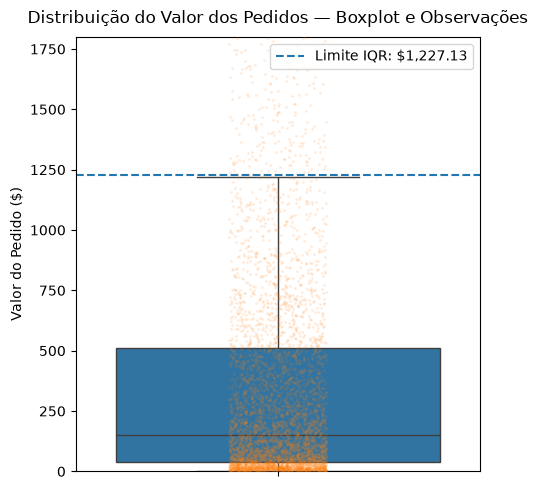

In [53]:
p95_order_value = orders["Order_Value"].quantile(0.95)

fig, ax = plt.subplots(figsize=(5, 5))

sns.boxplot(
    data=orders,
    y="Order_Value",
    showfliers=False,
    ax=ax
)

sns.stripplot(
    data=orders[orders["Order_Value"] <= p95_order_value],
    y="Order_Value",
    size=2,
    alpha=0.15,
    jitter=0.12,
    ax=ax
)

ax.axhline(
    order_iqr["upper_bound"],
    linestyle="--",
    linewidth=1.5,
    label=f"Limite IQR: ${order_iqr['upper_bound']:,.2f}"
)

ax.set_ylim(0, p95_order_value)

ax.set_title(
    "Distribuição do Valor dos Pedidos — Boxplot e Observações",
    pad=10
)

ax.set_xlabel("")
ax.set_ylabel("Valor do Pedido ($)")
ax.legend()

plt.tight_layout()
plt.show()

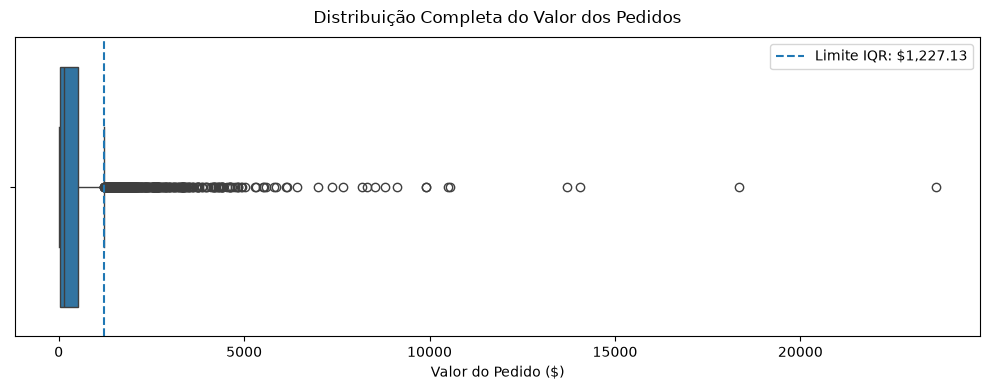

In [54]:
fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(
    data=orders,
    x="Order_Value",
    ax=ax
)

ax.axvline(
    order_iqr["upper_bound"],
    linestyle="--",
    linewidth=1.5,
    label=f"Limite IQR: ${order_iqr['upper_bound']:,.2f}"
)

ax.set_title("Distribuição Completa do Valor dos Pedidos", pad=10)
ax.set_xlabel("Valor do Pedido ($)")
ax.legend()

plt.tight_layout()
plt.show()

#### Interpretação da Distribuição dos Pedidos

A distribuição de Order_Value` mantém forte assimetria à direita mesmo após a consolidação das linhas de venda no nível de pedido.

O intervalo interquartil estabelece $1.227,13 como limite superior, acima do qual foram identificados 454 pedidos estatisticamente atípicos. Esses pedidos representam apenas 9,22% das 4.922 transações, mas concentram 51,09% da receita total.

A visualização completa evidencia a extensão da cauda superior, enquanto a perspectiva ampliada permite observar com maior clareza a região central da distribuição e a transição para os valores classificados como outliers.

Assim como observado na análise de Sales, a presença de valores extremos no nível dos pedidos possui relevância econômica e não constitui, isoladamente, evidência de erro ou problema de qualidade dos dados.

### 5.3 — Investigação de Outliers

As análises anteriores demonstraram que valores estatisticamente atípicos possuem elevada relevância financeira tanto no nível das linhas de venda quanto no nível dos pedidos consolidados.

Entretanto, um pedido de alto valor pode apresentar diferentes estruturas. Seu valor total pode estar associado a uma única linha de venda de elevada magnitude, à presença de múltiplos itens no mesmo pedido ou à combinação desses fatores.

Nesta etapa, a investigação passa da identificação estatística dos outliers para a análise de sua estrutura.

A questão exploratória é:

> Os pedidos de alto valor são caracterizados principalmente por linhas individuais de elevado valor, por uma maior quantidade de linhas no pedido ou pela combinação desses fatores?

In [55]:
order_structure = (
    df.groupby("Order ID", as_index=False)
      .agg(
          Order_Value=("Sales", "sum"),
          Line_Count=("Row ID", "count"),
          Max_Line_Value=("Sales", "max"),
          Mean_Line_Value=("Sales", "mean")
      )
)

In [56]:
print(f"Pedidos na tabela original: {len(orders):,}")
print(f"Pedidos na análise estrutural: {len(order_structure):,}")
print(
    "Order IDs distintos:",
    f"{order_structure['Order ID'].nunique():,}"
)
print(
    "Diferença de receita:",
    f"${orders['Order_Value'].sum() - order_structure['Order_Value'].sum():,.2f}"
)

Pedidos na tabela original: 4,922
Pedidos na análise estrutural: 4,922
Order IDs distintos: 4,922
Diferença de receita: $0.00


In [57]:
order_structure["Outlier_Status"] = (
    order_structure["Order_Value"] > order_iqr["upper_bound"]
).map({
    True: "Outlier",
    False: "Não Outlier"
})

In [58]:
order_structure["Outlier_Status"].value_counts()

Outlier_Status
Não Outlier    4468
Outlier         454
Name: count, dtype: int64

In [59]:
order_structure_comparison = (
    order_structure
    .groupby("Outlier_Status", as_index=False)
    .agg(
        Orders=("Order ID", "count"),
        Median_Line_Count=("Line_Count", "median"),
        Mean_Line_Count=("Line_Count", "mean"),
        Median_Max_Line_Value=("Max_Line_Value", "median"),
        Median_Mean_Line_Value=("Mean_Line_Value", "median")
    )
)

order_structure_comparison

,Outlier_Status,Orders,Median_Line_Count,Mean_Line_Count,Median_Max_Line_Value,Median_Mean_Line_Value
0,Não Outlier,4468,1.0,1.844002,98.340,71.23
1,Outlier,454,3.0,3.436123,1492.292,703.64


#### Concentração do Valor Dentro dos Pedidos

A comparação entre pedidos outliers e não outliers indica diferenças tanto na quantidade de linhas quanto na magnitude dos valores individuais.

Para distinguir melhor esses efeitos, é calculada a participação da maior linha de venda no valor total de cada pedido.

Essa medida permite identificar se os pedidos de alto valor tendem a ser dominados por uma única linha de grande magnitude ou se seu valor está mais distribuído entre múltiplas linhas.

In [60]:
order_structure["Max_Line_Share"] = (
    order_structure["Max_Line_Value"]
    / order_structure["Order_Value"]
)

In [61]:
order_structure_comparison = (
    order_structure
    .groupby("Outlier_Status", as_index=False)
    .agg(
        Orders=("Order ID", "count"),
        Median_Line_Count=("Line_Count", "median"),
        Mean_Line_Count=("Line_Count", "mean"),
        Median_Max_Line_Value=("Max_Line_Value", "median"),
        Median_Mean_Line_Value=("Mean_Line_Value", "median")
    )
)

order_structure_comparison

,Outlier_Status,Orders,Median_Line_Count,Mean_Line_Count,Median_Max_Line_Value,Median_Mean_Line_Value
0,Não Outlier,4468,1.0,1.844002,98.340,71.23
1,Outlier,454,3.0,3.436123,1492.292,703.64


In [62]:
outlier_order_structure = (
    order_structure[
        order_structure["Outlier_Status"] == "Outlier"
    ]
    .assign(
        Order_Structure=lambda x: x["Line_Count"].apply(
            lambda n: "Linha única" if n == 1 else "Múltiplas linhas"
        )
    )
)

In [63]:
outlier_structure_summary = (
    outlier_order_structure["Order_Structure"]
    .value_counts()
    .rename_axis("Estrutura")
    .reset_index(name="Pedidos")
)

outlier_structure_summary["Participação"] = (
    outlier_structure_summary["Pedidos"]
    / outlier_structure_summary["Pedidos"].sum()
)

outlier_structure_summary.style.format({
    "Pedidos": "{:,.0f}",
    "Participação": "{:.2%}"
})

,Estrutura,Pedidos,Participação
0,Múltiplas linhas,382,84.14%
1,Linha única,72,15.86%


#### Dominância da Maior Linha nos Pedidos Outliers

A maioria dos pedidos classificados como outliers é composta por múltiplas linhas. Entretanto, a presença de vários itens não significa necessariamente que o valor total esteja distribuído de maneira equilibrada entre eles.

Para avaliar essa estrutura, a análise é restringida aos pedidos outliers com múltiplas linhas, verificando o grau de concentração do valor total na maior linha de venda.

In [64]:
multi_line_outliers = outlier_order_structure[
    outlier_order_structure["Line_Count"] > 1
]

dominance_summary = pd.DataFrame({
    "Critério": [
        "Maior linha ≥ 50% do pedido",
        "Maior linha ≥ 75% do pedido",
        "Maior linha ≥ 90% do pedido"
    ],
    "Pedidos": [
        (multi_line_outliers["Max_Line_Share"] >= 0.50).sum(),
        (multi_line_outliers["Max_Line_Share"] >= 0.75).sum(),
        (multi_line_outliers["Max_Line_Share"] >= 0.90).sum()
    ]
})

dominance_summary["Participação"] = (
    dominance_summary["Pedidos"]
    / len(multi_line_outliers)
)

dominance_summary.style.format({
    "Pedidos": "{:,.0f}",
    "Participação": "{:.2%}"
})

,Critério,Pedidos,Participação
0,Maior linha ≥ 50% do pedido,328,85.86%
1,Maior linha ≥ 75% do pedido,205,53.66%
2,Maior linha ≥ 90% do pedido,118,30.89%


#### Interpretação da Estrutura dos Outliers

A investigação dos pedidos classificados como outliers demonstra que seu elevado valor está associado à combinação de dois fatores: maior quantidade de linhas por pedido e presença de linhas individuais de valor substancialmente superior.

Os pedidos outliers apresentam mediana de 3 linhas, frente a 1 nos demais pedidos. Entretanto, a diferença mais expressiva está na magnitude das vendas individuais: a mediana da maior linha passa de $98,34 nos pedidos não outliers para $1.492,29 nos pedidos outliers.

A maior linha representa uma mediana de 83,49% do valor total dos pedidos outliers. Além disso, 84,14% desses pedidos possuem múltiplas linhas, indicando que o elevado valor não está restrito a transações compostas por um único registro.

Ao considerar apenas os 382 pedidos outliers com múltiplas linhas, 85,86% possuem pelo menos metade do valor total concentrado na maior linha, 53,66% apresentam concentração igual ou superior a 75% e 30,89% concentram pelo menos 90% do valor em uma única linha.

Esses resultados indicam que a cauda superior da distribuição não é explicada apenas pela quantidade de linhas existentes nos pedidos. Embora os pedidos de alto valor tendam a possuir mais linhas, uma parcela relevante de seu valor permanece concentrada em vendas individuais de elevada magnitude.

Dessa forma, os outliers observados apresentam características compatíveis com a estrutura econômica das vendas analisadas e, até esta etapa, não há evidência suficiente para tratá-los automaticamente como erros ou removê-los do conjunto analítico.

## 6. Relações e Padrões Exploratórios

Após analisar individualmente as principais dimensões do negócio, esta seção investiga relações entre variáveis categóricas e operacionais.

O objetivo é identificar padrões que não são necessariamente visíveis nas análises isoladas, avaliando como diferentes dimensões se combinam na geração de receita e na estrutura dos pedidos.

### 6.1 — Categoria × Segmento

A análise individual mostrou que Consumer concentra a maior parcela da receita, enquanto as três categorias de produtos apresentam participação relativamente equilibrada no faturamento total.

Nesta etapa, essas duas dimensões são analisadas conjuntamente para verificar se a composição das vendas por categoria permanece semelhante entre os segmentos de clientes.

A questão exploratória é:

> A composição da receita entre Furniture, Office Supplies e Technology é semelhante nos diferentes segmentos de clientes ou existem padrões específicos de consumo?

In [65]:
category_segment = (
    df.groupby(["Segment", "Category"], as_index=False)
      .agg(
          Revenue=("Sales", "sum"),
          Orders=("Order ID", "nunique")
      )
)

category_segment["Revenue_Share_Within_Segment"] = (
    category_segment["Revenue"]
    / category_segment.groupby("Segment")["Revenue"].transform("sum")
)

In [66]:
category_segment.style.format({
    "Revenue": "${:,.2f}",
    "Orders": "{:,.0f}",
    "Revenue_Share_Within_Segment": "{:.2%}"
})

,Segment,Category,Revenue,Orders,Revenue_Share_Within_Segment
0,Consumer,Furniture,"$387,696.26",898,33.77%
1,Consumer,Office Supplies,"$359,352.61","1,888",31.30%
2,Consumer,Technology,"$401,011.66",795,34.93%
3,Corporate,Furniture,"$220,321.70",527,32.00%
4,Corporate,Office Supplies,"$224,130.54","1,123",32.55%
5,Corporate,Technology,"$244,041.84",447,35.45%
6,Home Office,Furniture,"$120,359.24",302,28.34%
7,Home Office,Office Supplies,"$121,939.19",665,28.71%
8,Home Office,Technology,"$182,402.37",277,42.95%


In [67]:
category_segment_share = (
    category_segment
    .pivot(
        index="Segment",
        columns="Category",
        values="Revenue_Share_Within_Segment"
    )
)

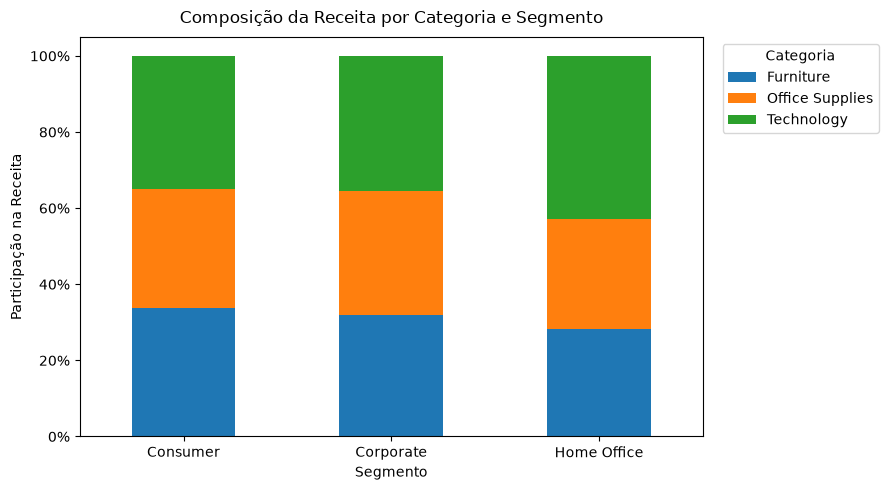

In [68]:
ax = category_segment_share.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

ax.set_title("Composição da Receita por Categoria e Segmento", pad=10)
ax.set_xlabel("Segmento")
ax.set_ylabel("Participação na Receita")
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

ax.legend(
    title="Categoria",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Interpretação

A composição da receita apresenta comportamento semelhante nos segmentos Consumer e Corporate, com distribuição relativamente equilibrada entre Furniture, Office Supplies e Technology.

No segmento Consumer, as participações variam entre 31,30% e 34,93%, enquanto em Corporate permanecem entre 32,00% e 35,45%, indicando baixa concentração em uma categoria específica.

O segmento Home Office apresenta uma composição distinta. Technology representa 42,95% de sua receita, frente a 28,34% de Furniture e 28,71% de Office Supplies.

A análise também evidencia que maior frequência de pedidos não implica necessariamente maior participação na receita. Office Supplies, por exemplo, apresenta maior número de pedidos nos três segmentos, mas não lidera o faturamento em nenhum deles.

Os resultados sugerem diferenças na composição econômica das compras entre os segmentos, especialmente em Home Office. A origem dessas diferenças — como subcategorias, produtos ou valores por pedido — exige análises mais específicas e não é inferida nesta etapa exploratória.

### 6.2 — Região × Categoria

A análise regional anterior demonstrou diferenças no volume de receita e no valor médio dos pedidos entre West, East, Central e South.

Nesta etapa, a região é analisada em conjunto com a categoria de produto para verificar se essas diferenças também estão associadas à composição das vendas.

A questão exploratória é:

> A participação de Furniture, Office Supplies e Technology permanece semelhante entre as regiões ou existem diferenças relevantes no mix de receita regional?

In [69]:
region_category = (
    df.groupby(["Region", "Category"], as_index=False)
      .agg(
          Revenue=("Sales", "sum"),
          Orders=("Order ID", "nunique")
      )
)

region_category["Revenue_Share_Within_Region"] = (
    region_category["Revenue"]
    / region_category.groupby("Region")["Revenue"].transform("sum")
)

In [70]:
region_category.style.format({
    "Revenue": "${:,.2f}",
    "Orders": "{:,.0f}",
    "Revenue_Share_Within_Region": "{:.2%}"
})

,Region,Category,Revenue,Orders,Revenue_Share_Within_Region
0,Central,Furniture,"$160,317.46",393,32.54%
1,Central,Office Supplies,"$163,590.24",865,33.21%
2,Central,Technology,"$168,739.21",348,34.25%
3,East,Furniture,"$206,180.02",480,30.81%
4,East,Office Supplies,"$199,940.81","1,048",29.88%
5,East,Technology,"$263,116.53",436,39.32%
6,South,Furniture,"$116,531.48",272,29.95%
7,South,Office Supplies,"$124,424.77",613,31.97%
8,South,Technology,"$148,195.21",252,38.08%
9,West,Furniture,"$245,348.25",582,34.55%


In [71]:
region_category_share = (
    region_category
    .pivot(
        index="Region",
        columns="Category",
        values="Revenue_Share_Within_Region"
    )
)

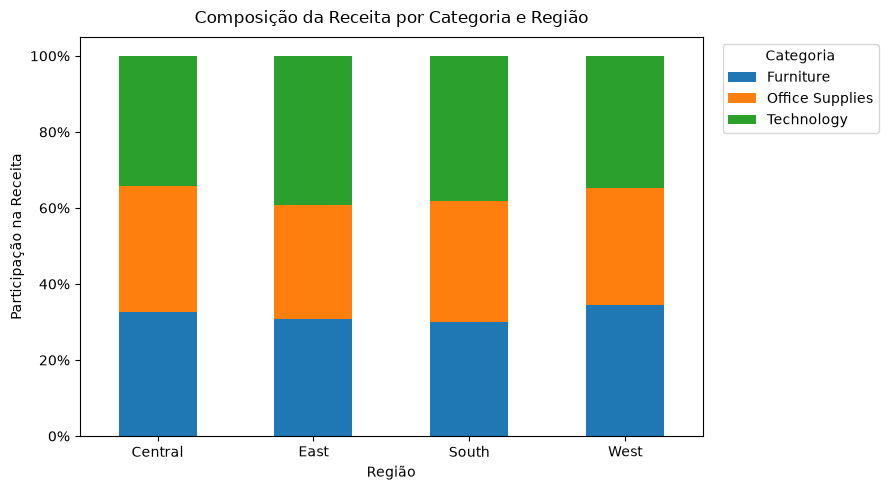

In [72]:
ax = region_category_share.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

ax.set_title("Composição da Receita por Categoria e Região", pad=10)
ax.set_xlabel("Região")
ax.set_ylabel("Participação na Receita")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

ax.legend(
    title="Categoria",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Interpretação

A composição da receita por categoria apresenta diferenças moderadas entre as regiões.

Central possui o mix mais equilibrado, com participações entre 32,54% e 34,25%. West também apresenta distribuição relativamente uniforme, embora Office Supplies tenha participação ligeiramente inferior às demais categorias.

Em East e South, observa-se maior participação relativa de Technology, que representa respectivamente 39,32% e 38,08% da receita regional. Nessas regiões, a composição do faturamento apresenta maior concentração nessa categoria quando comparada a Central e West.

Assim como observado na análise por segmento, Office Supplies apresenta o maior número de pedidos em todas as regiões, mas não lidera a receita regional. Esse comportamento indica que frequência de pedidos e participação no faturamento representam dimensões distintas da atividade comercial.

Os resultados evidenciam diferenças no mix de receita entre as regiões, especialmente pela maior participação de Technology em East e South. As possíveis causas desse comportamento exigem análises mais específicas de produtos, subcategorias e estrutura dos pedidos e não são inferidas nesta etapa exploratória.

### 6.3 — Shipping Days × Ship Mode

A variável Shipping Days representa o intervalo entre a data do pedido e a data de envio. Como um mesmo pedido pode conter múltiplas linhas, analisar essa variável diretamente na granularidade das linhas de venda atribuiria maior peso aos pedidos com mais itens.

Por esse motivo, a análise logística é realizada na granularidade do pedido, garantindo que cada Order ID contribua uma única vez para as estatísticas.

A questão exploratória é:

> Como o tempo de envio se distribui entre os diferentes modos de envio e quais diferenças operacionais podem ser observadas entre eles?

In [73]:
shipping_consistency = (
    df.groupby("Order ID")
      .agg(
          Ship_Mode_Count=("Ship Mode", "nunique"),
          Shipping_Days_Count=("Shipping Days", "nunique")
      )
)

print(
    "Pedidos com mais de um Ship Mode:",
    (shipping_consistency["Ship_Mode_Count"] > 1).sum()
)

print(
    "Pedidos com mais de um Shipping Days:",
    (shipping_consistency["Shipping_Days_Count"] > 1).sum()
)

Pedidos com mais de um Ship Mode: 0
Pedidos com mais de um Shipping Days: 0


In [74]:
shipping_orders = (
    df.groupby("Order ID", as_index=False)
      .agg(
          Ship_Mode=("Ship Mode", "first"),
          Shipping_Days=("Shipping Days", "first")
      )
)

In [75]:
print(f"Pedidos esperados: {df['Order ID'].nunique():,}")
print(f"Pedidos na tabela logística: {len(shipping_orders):,}")
print(
    "Order IDs distintos:",
    f"{shipping_orders['Order ID'].nunique():,}"
)

Pedidos esperados: 4,922
Pedidos na tabela logística: 4,922
Order IDs distintos: 4,922


In [76]:
shipping_mode_summary = (
    shipping_orders
    .groupby("Ship_Mode")
    .agg(
        Orders=("Order ID", "count"),
        Mean_Shipping_Days=("Shipping_Days", "mean"),
        Median_Shipping_Days=("Shipping_Days", "median"),
        Min_Shipping_Days=("Shipping_Days", "min"),
        Max_Shipping_Days=("Shipping_Days", "max")
    )
    .sort_values("Mean_Shipping_Days")
)

shipping_mode_summary.style.format({
    "Orders": "{:,.0f}",
    "Mean_Shipping_Days": "{:.2f}",
    "Median_Shipping_Days": "{:.1f}",
    "Min_Shipping_Days": "{:.0f}",
    "Max_Shipping_Days": "{:.0f}"
})

,Orders,Mean_Shipping_Days,Median_Shipping_Days,Min_Shipping_Days,Max_Shipping_Days
Ship_Mode,,,,,
Same Day,261,0.05,0.0,0,1
First Class,772,2.19,2.0,1,4
Second Class,944,3.24,3.0,1,5
Standard Class,"2,945",5.00,5.0,3,7


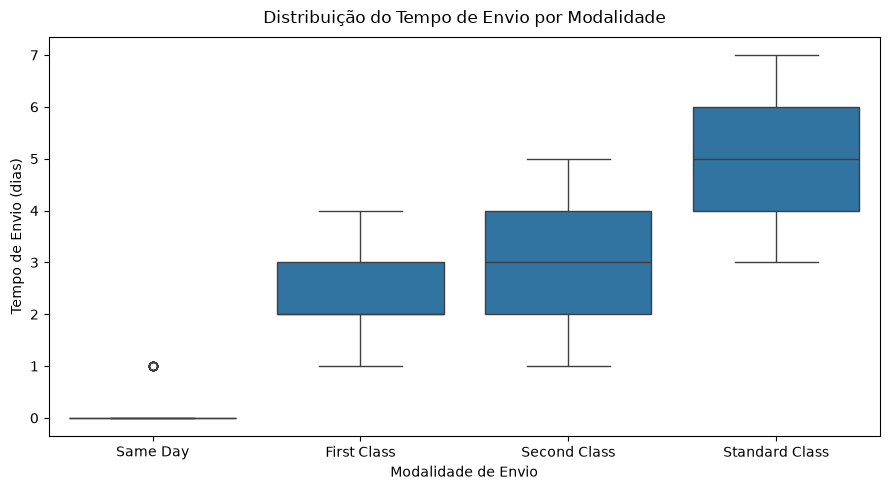

In [77]:
shipping_mode_order = [
    "Same Day",
    "First Class",
    "Second Class",
    "Standard Class"
]

fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=shipping_orders,
    x="Ship_Mode",
    y="Shipping_Days",
    order=shipping_mode_order,
    ax=ax
)

ax.set_title("Distribuição do Tempo de Envio por Modalidade", pad=10)
ax.set_xlabel("Modalidade de Envio")
ax.set_ylabel("Tempo de Envio (dias)")

plt.tight_layout()
plt.show()

#### Interpretação

A análise por pedido evidencia diferenças claras no tempo de envio entre as modalidades disponíveis.

Same Day apresenta o menor tempo de envio, com mediana de 0 dias e média de 0,05 dia. First Class apresenta mediana de 2 dias, seguida por Second Class, com 3 dias, e Standard Class, com 5 dias.

A distribuição confirma uma progressão consistente dos tempos de envio entre as modalidades. First Class varia entre 1 e 4 dias, Second Class entre 1 e 5 dias e Standard Class entre 3 e 7 dias.

Além das diferenças no tempo de envio, observa-se forte diferença na utilização das modalidades. Standard Class concentra 2.945 dos 4.922 pedidos, enquanto Same Day é utilizado em apenas 261.

A proximidade entre média e mediana em cada modalidade indica que os tempos típicos de envio são coerentes com o comportamento central observado nas respectivas distribuições.

Os resultados demonstram uma associação clara entre Ship Mode e Shipping Days no conjunto analisado. Entretanto, esta análise descreve o comportamento observado e não permite concluir, isoladamente, que a modalidade de envio seja a causa das diferenças, nem avaliar cumprimento de prazos ou desempenho logístico, pois o conjunto não contém uma referência explícita de prazo prometido ao cliente.

### 6.4 — Relação entre Valor do Pedido e Estrutura do Pedido

A investigação dos outliers demonstrou que pedidos de alto valor tendem a combinar maior quantidade de linhas com vendas individuais de maior magnitude.

Nesta etapa, a análise é ampliada para o conjunto completo de pedidos, independentemente de sua classificação como outlier, buscando compreender a relação geral entre a estrutura do pedido e seu valor econômico.

Como a tabela order_structure já representa uma observação por Order ID, ela será reutilizada sem necessidade de nova agregação.

A questão exploratória é:

> Pedidos compostos por maior número de linhas tendem a apresentar maior valor total, e qual é o comportamento dessa relação no conjunto completo de transações?

In [78]:
order_value_by_lines = (
    order_structure
    .groupby("Line_Count", as_index=False)
    .agg(
        Orders=("Order ID", "count"),
        Median_Order_Value=("Order_Value", "median"),
        Mean_Order_Value=("Order_Value", "mean")
    )
    .sort_values("Line_Count")
)

order_value_by_lines["Order_Share"] = (
    order_value_by_lines["Orders"]
    / order_value_by_lines["Orders"].sum()
)

order_value_by_lines.style.format({
    "Line_Count": "{:,.0f}",
    "Orders": "{:,.0f}",
    "Median_Order_Value": "${:,.2f}",
    "Mean_Order_Value": "${:,.2f}",
    "Order_Share": "{:.2%}"
})

,Line_Count,Orders,Median_Order_Value,Mean_Order_Value,Order_Share
0,1,"2,499",$51.18,$208.36,50.77%
1,2,"1,198",$192.30,$443.61,24.34%
2,3,591,$392.06,$768.04,12.01%
3,4,332,$548.02,$933.81,6.75%
4,5,153,$874.31,"$1,330.05",3.11%
5,6,69,$760.80,"$1,048.97",1.40%
6,7,48,"$1,356.20","$2,183.23",0.98%
7,8,15,$997.83,"$1,328.71",0.30%
8,9,10,"$1,070.88","$1,751.27",0.20%
9,10,3,"$3,385.61","$4,479.52",0.06%


#### Associação entre Quantidade de Linhas e Valor do Pedido

A análise descritiva sugere aumento do valor típico dos pedidos à medida que cresce sua quantidade de linhas, especialmente nos grupos com maior número de observações.

Entretanto, a distribuição de Order_Value é fortemente assimétrica e os pedidos com grande número de linhas são pouco frequentes. Por esse motivo, a relação é avaliada por meio dos coeficientes de correlação de Pearson e Spearman.

Pearson mede a intensidade da associação linear entre as variáveis, enquanto Spearman avalia se existe uma tendência monotônica, sendo menos sensível à magnitude dos valores extremos.

In [79]:
pearson_corr = order_structure[
    ["Line_Count", "Order_Value"]
].corr(method="pearson").iloc[0, 1]

spearman_corr = order_structure[
    ["Line_Count", "Order_Value"]
].corr(method="spearman").iloc[0, 1]

correlation_summary = pd.DataFrame({
    "Método": ["Pearson", "Spearman"],
    "Correlação": [pearson_corr, spearman_corr]
})

correlation_summary.style.format({
    "Correlação": "{:.3f}"
})

,Método,Correlação
0,Pearson,0.376
1,Spearman,0.550


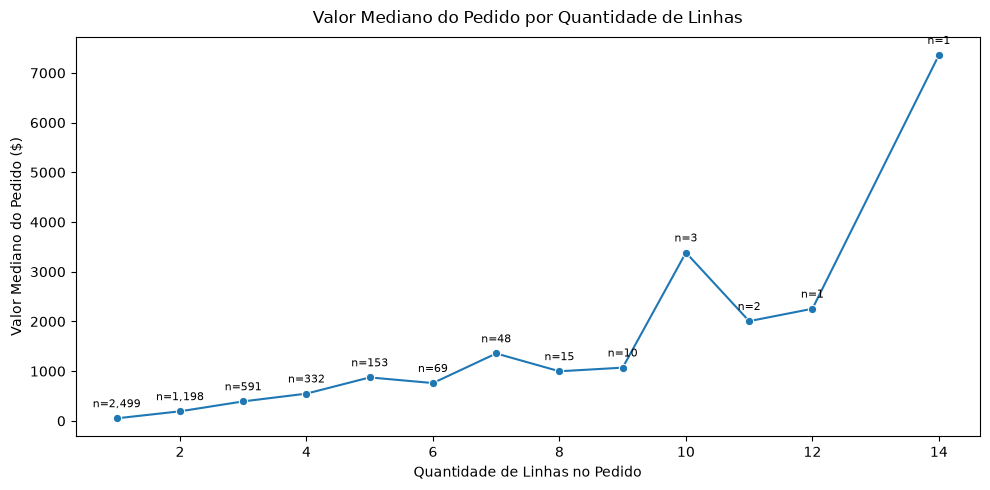

In [80]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=order_value_by_lines,
    x="Line_Count",
    y="Median_Order_Value",
    marker="o",
    ax=ax
)

ax.set_title(
    "Valor Mediano do Pedido por Quantidade de Linhas",
    pad=10
)
ax.set_xlabel("Quantidade de Linhas no Pedido")
ax.set_ylabel("Valor Mediano do Pedido ($)")

for _, row in order_value_by_lines.iterrows():
    ax.annotate(
        f"n={int(row['Orders']):,}",
        (row["Line_Count"], row["Median_Order_Value"]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

plt.tight_layout()
plt.show()

#### Interpretação

A análise do conjunto completo de pedidos evidencia uma associação positiva entre a quantidade de linhas e o valor total da transação.

Nos grupos com maior número de observações, o valor mediano do pedido cresce de $51,18 para pedidos com uma linha para $192,30 com duas linhas, $392,06 com três, $548,02 com quatro e $874,31 com cinco linhas.

Essa relação também é observada nos coeficientes de correlação. Pearson apresenta valor de 0,376, indicando associação linear positiva moderada, enquanto Spearman alcança 0,550, evidenciando uma associação monotônica positiva mais pronunciada.

A diferença entre os coeficientes é compatível com o comportamento observado nos dados: o valor dos pedidos tende a aumentar conforme cresce a quantidade de linhas, mas essa progressão não ocorre de maneira perfeitamente linear.

A partir das maiores quantidades de linhas, a interpretação exige cautela devido à redução acentuada do número de observações. Pedidos com oito ou mais linhas representam uma parcela muito pequena da base, e alguns pontos extremos são formados por apenas um ou poucos pedidos. Por esse motivo, as oscilações observadas nessa região não são interpretadas como padrões gerais do negócio.

Os resultados indicam, portanto, que pedidos mais estruturados em número de linhas tendem a apresentar maior valor econômico, embora a quantidade de linhas não explique isoladamente a magnitude das transações. Como observado anteriormente na investigação dos outliers, o valor individual das linhas também desempenha papel relevante.

## 7. Consolidação da Análise Exploratória

A análise exploratória permitiu compreender a estrutura geral das vendas, identificar padrões temporais, dimensionais e operacionais e avaliar a presença de valores estatisticamente atípicos.

Esta seção consolida as principais evidências encontradas e transforma os resultados exploratórios em questões analíticas que orientarão as etapas especializadas do projeto.

7.1 — Principais Achados
A exploração dos dados revelou os seguintes padrões principais:

Estrutura geral do negócio

O período analisado compreende 4.922 pedidos realizados por 793 clientes, totalizando aproximadamente $2,26 milhões em receita. O valor médio por pedido é de $459,42.

As três categorias apresentam participação relativamente equilibrada na receita total, com Technology representando 36,6%, Furniture 32,2% e Office Supplies 31,2%. No nível de subcategoria, a receita apresenta maior concentração, embora não seja observado um padrão clássico de concentração 80/20.

Segmentos e regiões

Consumer concentra 50,77% da receita e o maior número de clientes e pedidos, enquanto Home Office apresenta menor participação total, mas maior valor médio por pedido.

Regionalmente, West possui a maior receita total, enquanto East apresenta o maior valor médio por pedido. A composição das vendas também varia entre regiões e segmentos: Technology possui participação particularmente elevada em Home Office e maior peso relativo em East e South.

Comportamento temporal

A série mensal apresenta variações relevantes ao longo do período analisado e indícios de mudança no nível de receita ao longo do tempo.

A comparação entre meses evidencia comportamento recorrente em determinados períodos. September, November e December apresentam receita acima da média mensal de seus respectivos anos nos quatro ciclos observados, enquanto January, February, April, June e July permanecem abaixo da média nos quatro anos.

Esses resultados sugerem a presença de componente sazonal, mas os quatro ciclos anuais disponíveis não são suficientes, isoladamente, para estabelecer uma conclusão definitiva sobre tendência ou sazonalidade.

Distribuições e valores atípicos

As distribuições de Sales e Order_Value apresentam forte assimetria à direita.

No nível das linhas de venda, 11,68% dos registros classificados como outliers pelo critério do IQR concentram 64,33% da receita. No nível dos pedidos, 9,22% das transações classificadas como outliers concentram 51,09% da receita.

A investigação desses casos mostrou que os valores extremos possuem relevância econômica e estão associados, entre outros fatores, a vendas individuais de elevada magnitude. Não foi identificada evidência suficiente para tratá-los automaticamente como erros ou removê-los da base analítica.

Estrutura dos pedidos

Pedidos de alto valor tendem a combinar maior quantidade de linhas com linhas individuais de maior magnitude. Entre os pedidos outliers com múltiplas linhas, 85,86% possuem pelo menos metade do valor total concentrado em sua maior linha.

Considerando todos os pedidos, existe associação positiva entre quantidade de linhas e valor da transação. A correlação de Spearman de 0,550 indica uma relação monotônica positiva, embora não perfeitamente linear.

Comportamento logístico

Os tempos de envio apresentam diferenças claras entre as modalidades. As medianas observadas são de 0 dias para Same Day, 2 para First Class, 3 para Second Class e 5 para Standard Class.

Standard Class é também a modalidade predominante, utilizada em 2.945 dos 4.922 pedidos. Esses resultados descrevem diferenças operacionais entre modalidades, mas não permitem avaliar cumprimento de SLA ou atraso, pois não existe no conjunto uma variável de prazo prometido.

### 7.2 — Hipóteses e Questões Analíticas

Os padrões identificados durante a análise exploratória levantam questões que exigem investigação mais específica antes de qualquer conclusão de negócio.

Essas questões orientam as próximas etapas do projeto e funcionam como hipóteses analíticas a serem avaliadas nos notebooks especializados.

**Vendas**

A evolução mensal da receita sugere mudanças no desempenho comercial ao longo do período analisado.

Questões para aprofundamento:

- Como a receita evoluiu entre os anos e quais períodos contribuíram mais para seu crescimento ou redução?
- O desempenho observado é explicado principalmente por aumento no número de pedidos, por mudanças no valor dos pedidos ou pela combinação desses fatores?
- Quais segmentos, regiões e categorias mais contribuíram para as variações da receita?

**Clientes**

O segmento Consumer concentra a maior parcela da receita e do volume de pedidos, enquanto diferenças de valor médio são observadas entre os segmentos.

Questões para aprofundamento:

- Como a receita está distribuída entre os clientes?
- Existe concentração relevante do faturamento em um grupo reduzido de clientes?
- Quais clientes apresentam maior frequência de compra e maior valor acumulado?
- Existem diferenças relevantes no comportamento de compra entre os segmentos?

**Produtos**

A receita é relativamente equilibrada entre as categorias, mas apresenta maior diferenciação no nível de subcategorias e produtos. Technology também ganha maior participação em determinados segmentos e regiões.

Questões para aprofundamento:

- Quais produtos e subcategorias possuem maior contribuição para a receita?
- A concentração observada nos valores extremos está associada a determinados produtos ou subcategorias?
- Quais produtos combinam alta frequência de pedidos e elevada contribuição financeira?
- As diferenças de composição observadas entre segmentos e regiões permanecem no nível de subcategoria e produto?

**Logística**

Os tempos de envio apresentam comportamento claramente distinto entre as modalidades, e Standard Class concentra a maior parte dos pedidos.

Questões para aprofundamento:

- Como os tempos de envio se comportam dentro de cada modalidade?
- Existem diferenças logísticas relevantes entre regiões, categorias ou segmentos?
- Determinados grupos de pedidos apresentam tempos de envio sistematicamente superiores aos demais?
- Como o perfil de utilização das modalidades varia entre diferentes dimensões do negócio?

Na ausência de uma variável de prazo prometido, a análise logística será limitada ao tempo de envio observado e não interpretará tempos maiores como atrasos.

**Série Temporal e Forecasting**

A análise mensal identificou indícios de mudança no nível de receita e comportamento recorrente em determinados meses, especialmente September, November e December.

Questões para aprofundamento:

- Existe tendência estatisticamente identificável na série de receita?
- O padrão mensal observado caracteriza um componente sazonal consistente?
- Qual é a magnitude relativa dos componentes de tendência, sazonalidade e variação residual?
- A série apresenta estrutura suficiente para construção de modelos de previsão?
- Qual abordagem de forecasting apresenta melhor desempenho fora da amostra?

### 7.3 — Encaminhamento para as Análises Especializadas

A análise exploratória estabeleceu a base analítica para as próximas etapas do projeto, identificando padrões que exigem aprofundamento em contextos específicos.

Os resultados e hipóteses levantados serão desenvolvidos nos seguintes notebooks:

- 04_sales_analysis.ipynb — aprofundamento do desempenho comercial, evolução da receita, estrutura dos pedidos e contribuição das principais dimensões de negócio.

- 05_customer_analysis.ipynb — análise do comportamento dos clientes, frequência de compra, valor acumulado, concentração de receita e diferenças entre segmentos.

- 06_product_analysis.ipynb — investigação da contribuição de categorias, subcategorias e produtos, incluindo concentração de receita e participação nos valores de maior magnitude.

- 07_logistics_analysis.ipynb — aprofundamento dos tempos e modalidades de envio e de suas diferenças entre dimensões do negócio, respeitando as limitações das variáveis disponíveis.

- 08_time_series_forecasting.ipynb — análise formal da série temporal, investigação de tendência e sazonalidade e avaliação de abordagens de previsão.

O EDA não busca substituir essas análises especializadas. Seu papel é estabelecer evidências iniciais, identificar relações relevantes e definir questões que possam ser investigadas de forma direcionada nas etapas seguintes.

Com essa estrutura, o projeto avança de uma exploração ampla dos dados para análises progressivamente mais específicas, mantendo rastreabilidade entre evidências, hipóteses e conclusões.